# Ablation Study — Results Visualization

Notebook này trực quan hóa kết quả thực nghiệm Ablation Study của DeepKoopFormer trên bốn bộ dữ liệu: Electricity, Financial, CMIP6 Wind và CMIP6 Pressure.

Các kết quả được đọc từ thư mục `results/ablation_merged_1344`. Notebook không huấn luyện lại mô hình hoặc cập nhật trọng số.

Các biểu đồ được xuất vào thư mục `figures/` để phục vụ báo cáo nghiên cứu.

## 1. Model Performance Comparison

Phần này so sánh hiệu năng của sáu mô hình Ablation thông qua Mean Test MSE.

Với mỗi dataset, giá trị Test MSE của từng mô hình được lấy trung bình trên 56 cấu hình, tương ứng 7 patch lengths và 8 forecast horizons.

Biểu đồ thanh ngang được sử dụng để so sánh các mô hình trong cùng dataset.

Giá trị MSE càng thấp thể hiện sai số dự báo càng nhỏ.

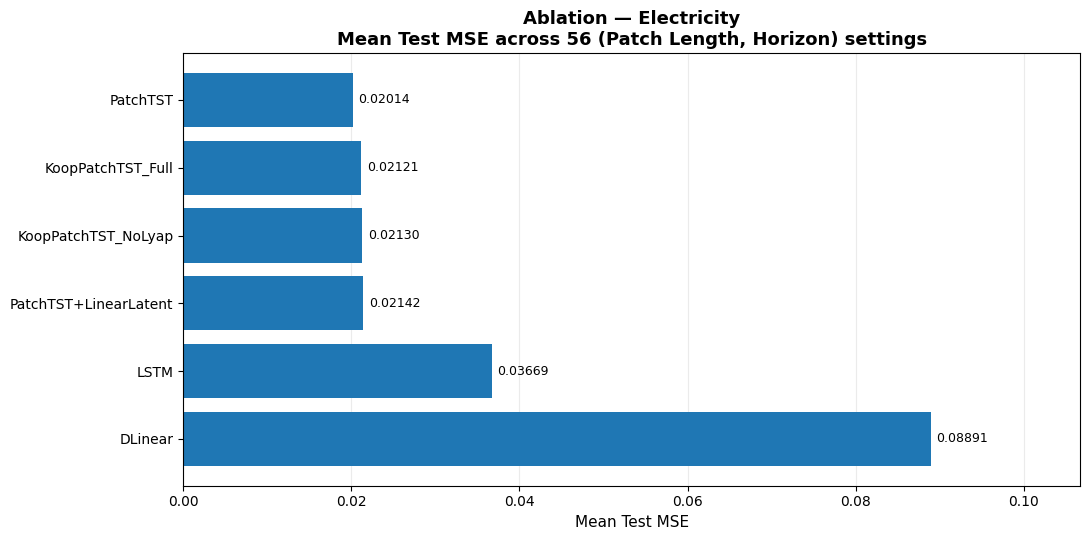

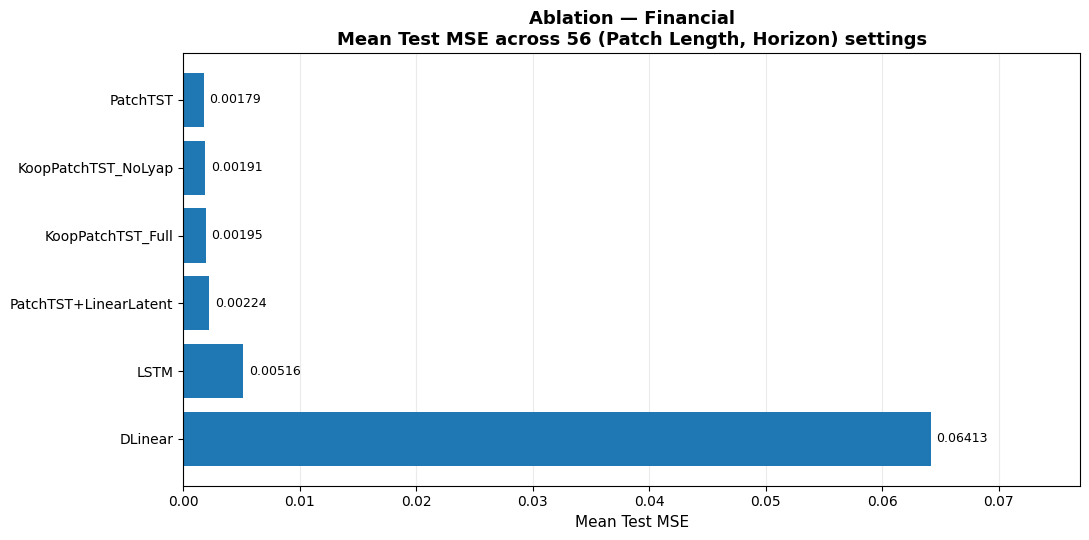

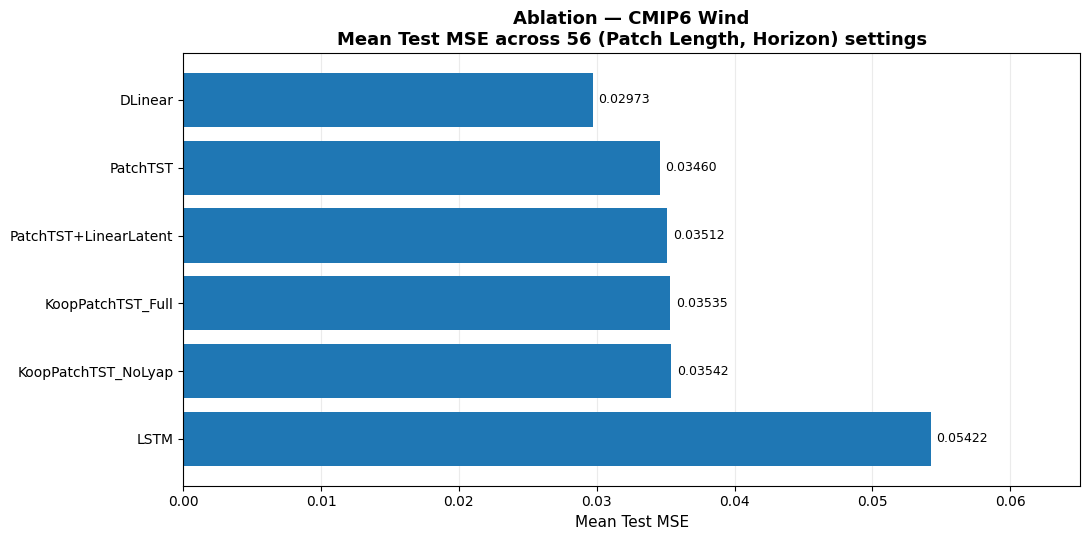

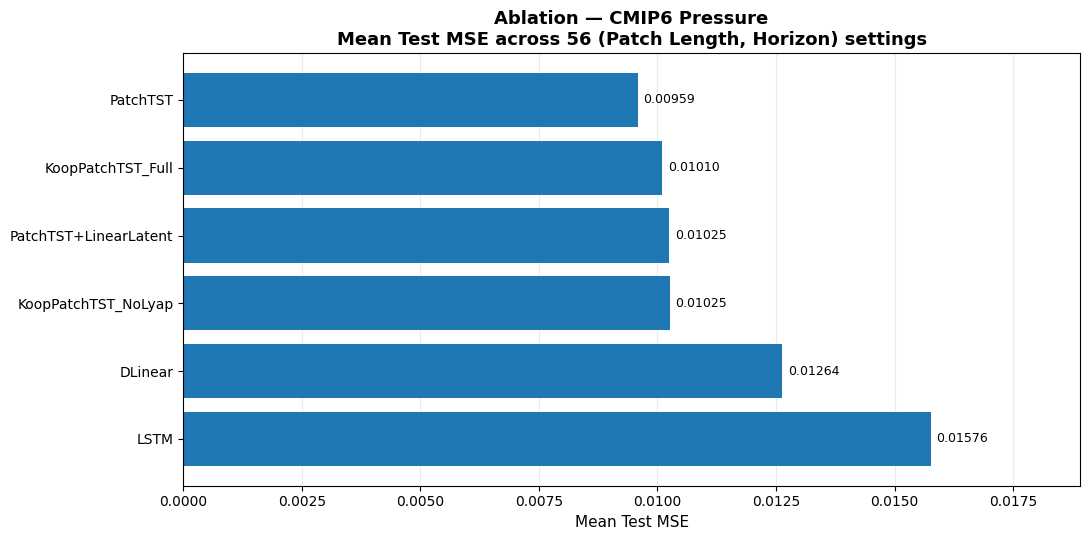

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate experiment directory
EXPERIMENT_DIR = next(
    (
        p / "experiments" / "05_ablation"
        for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "experiments" / "05_ablation"
            / "04_ablation_visualization.ipynb"
        ).is_file()
    ),
    None
)

if EXPERIMENT_DIR is None:
    raise FileNotFoundError(
        "Cannot locate 05_ablation experiment directory."
    )

# Read-only experimental results
RESULTS_DIR = (
    EXPERIMENT_DIR / "results" / "ablation_merged_1344"
)

METRICS_PATH = RESULTS_DIR / "metrics.csv"

# Figure outputs
FIGURE_DIR = EXPERIMENT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


assert METRICS_PATH.is_file()

df = pd.read_csv(METRICS_PATH)

# 1. Validate results
test = df[
    df["Set"].astype(str).str.lower() == "test"
].copy()

assert len(test) == 1344
assert test["Dataset"].nunique() == 4
assert test["Model"].nunique() == 6
assert test["PatchLen"].nunique() == 7
assert test["Horizon"].nunique() == 8
assert (test["Epochs"] == 4000).all()
assert np.isfinite(test[["MSE", "MAE"]]).all().all()

keys = ["Dataset", "Model", "PatchLen", "Horizon"]
assert not test.duplicated(keys).any()

# 2. Aggregate by dataset and model
MODEL_SUMMARY = (
    test.groupby(
        ["Dataset", "Model"], as_index=False
    )
    .agg(
        Runs=("MSE", "size"),
        MSE_Mean=("MSE", "mean"),
        MSE_Median=("MSE", "median"),
        MAE_Mean=("MAE", "mean")
    )
)

assert len(MODEL_SUMMARY) == 24
assert (MODEL_SUMMARY["Runs"] == 56).all()

# 3. Generate one figure per dataset
DATASET_ORDER = [
    "Electricity",
    "Financial",
    "CMIP6 Wind",
    "CMIP6 Pressure"
]

DATASET_ORDER = [
    "Electricity",
    "Financial",
    "CMIP6 Wind",
    "CMIP6 Pressure"
]

MODEL_ORDER = [
    "DLinear",
    "LSTM",
    "PatchTST",
    "PatchTST+LinearLatent",
    "KoopPatchTST_NoLyap",
    "KoopPatchTST_Full"
]

PATCH_LENGTHS = [70, 80, 90, 100, 110, 120, 130]
HORIZONS = [2, 4, 6, 8, 10, 12, 14, 16]

PATCHES = PATCH_LENGTHS


saved_figures = []

for dataset in DATASET_ORDER:

    subset = (
        MODEL_SUMMARY[
            MODEL_SUMMARY["Dataset"] == dataset
        ]
        .sort_values("MSE_Mean", ascending=True)
    )

    assert len(subset) == 6

    fig, ax = plt.subplots(figsize=(11, 5.5))

    bars = ax.barh(
        subset["Model"],
        subset["MSE_Mean"]
    )

    ax.invert_yaxis()

    ax.set_xlabel("Mean Test MSE", fontsize=11)

    ax.set_title(
        f"Ablation — {dataset}\n"
        "Mean Test MSE across 56 (Patch Length, Horizon) settings",
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.bar_label(
        bars,
        fmt="%.5f",
        padding=4,
        fontsize=9
    )

    ax.set_xlim(
        0,
        subset["MSE_Mean"].max() * 1.20
    )

    fig.tight_layout()

    filename = (
        "fig01_model_mse_"
        + dataset.lower().replace(" ", "_")
        + ".png"
    )

    save_path = FIGURE_DIR / filename

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    saved_figures.append(save_path)

    plt.show()
    
    plt.close(fig)


## 2. Patch Length and Forecast Horizon Heatmaps

Phần này phân tích hiệu năng dự báo của từng mô hình theo hai siêu tham số:

- Patch Length (P): Độ dài chuỗi đầu vào.
- Forecast Horizon (H): Số bước thời gian cần dự báo.

Với mỗi dataset, sáu heatmap được bố trí theo dạng 2 hàng × 3 cột, tương ứng sáu mô hình Ablation.

Mỗi heatmap biểu diễn ma trận Test MSE kích thước 7 × 8.

Các mô hình trong cùng dataset sử dụng chung thang màu để thuận tiện so sánh.

Ô có Test MSE thấp nhất của từng mô hình được đánh dấu nhằm xác định cấu hình tốt nhất trong phạm vi grid đã thử nghiệm.

Phân tích giúp quan sát mức độ nhạy cảm của mô hình đối với lựa chọn patch length và forecast horizon.

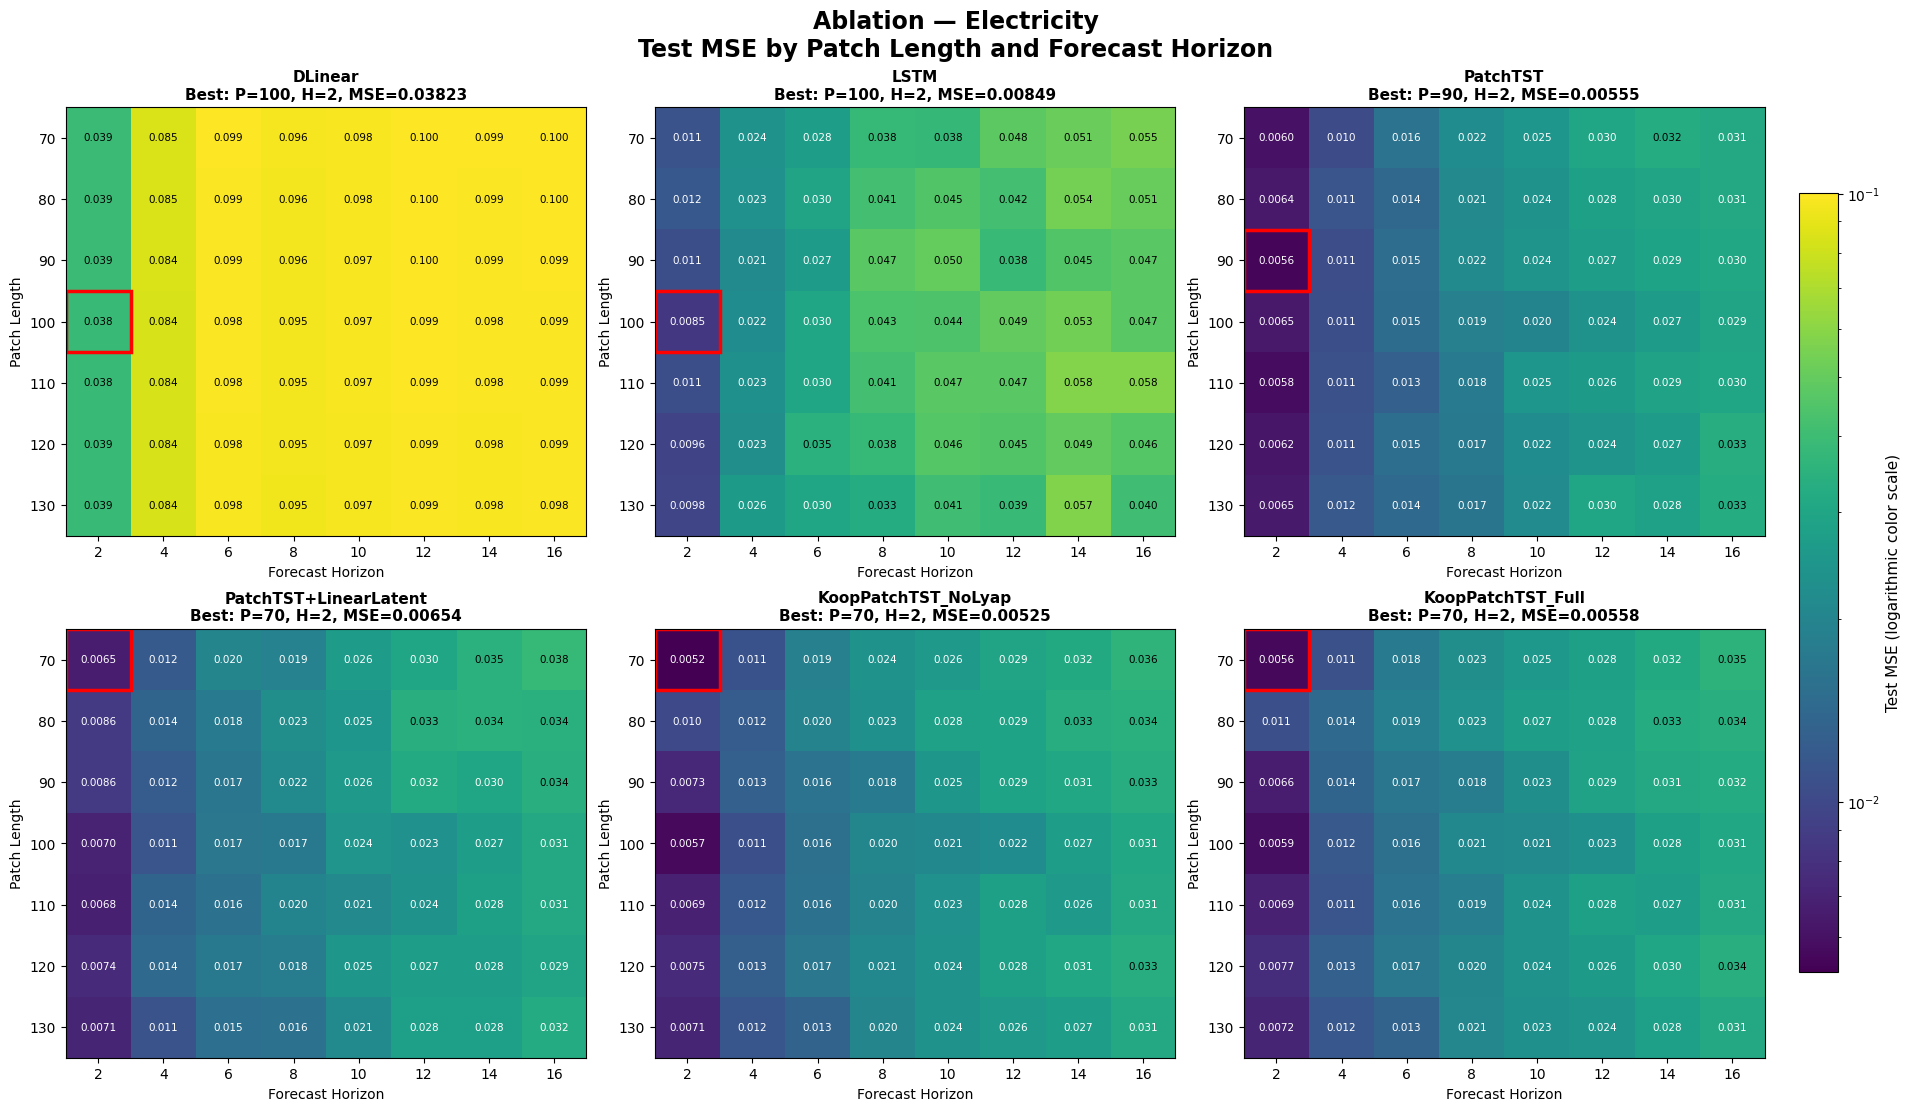

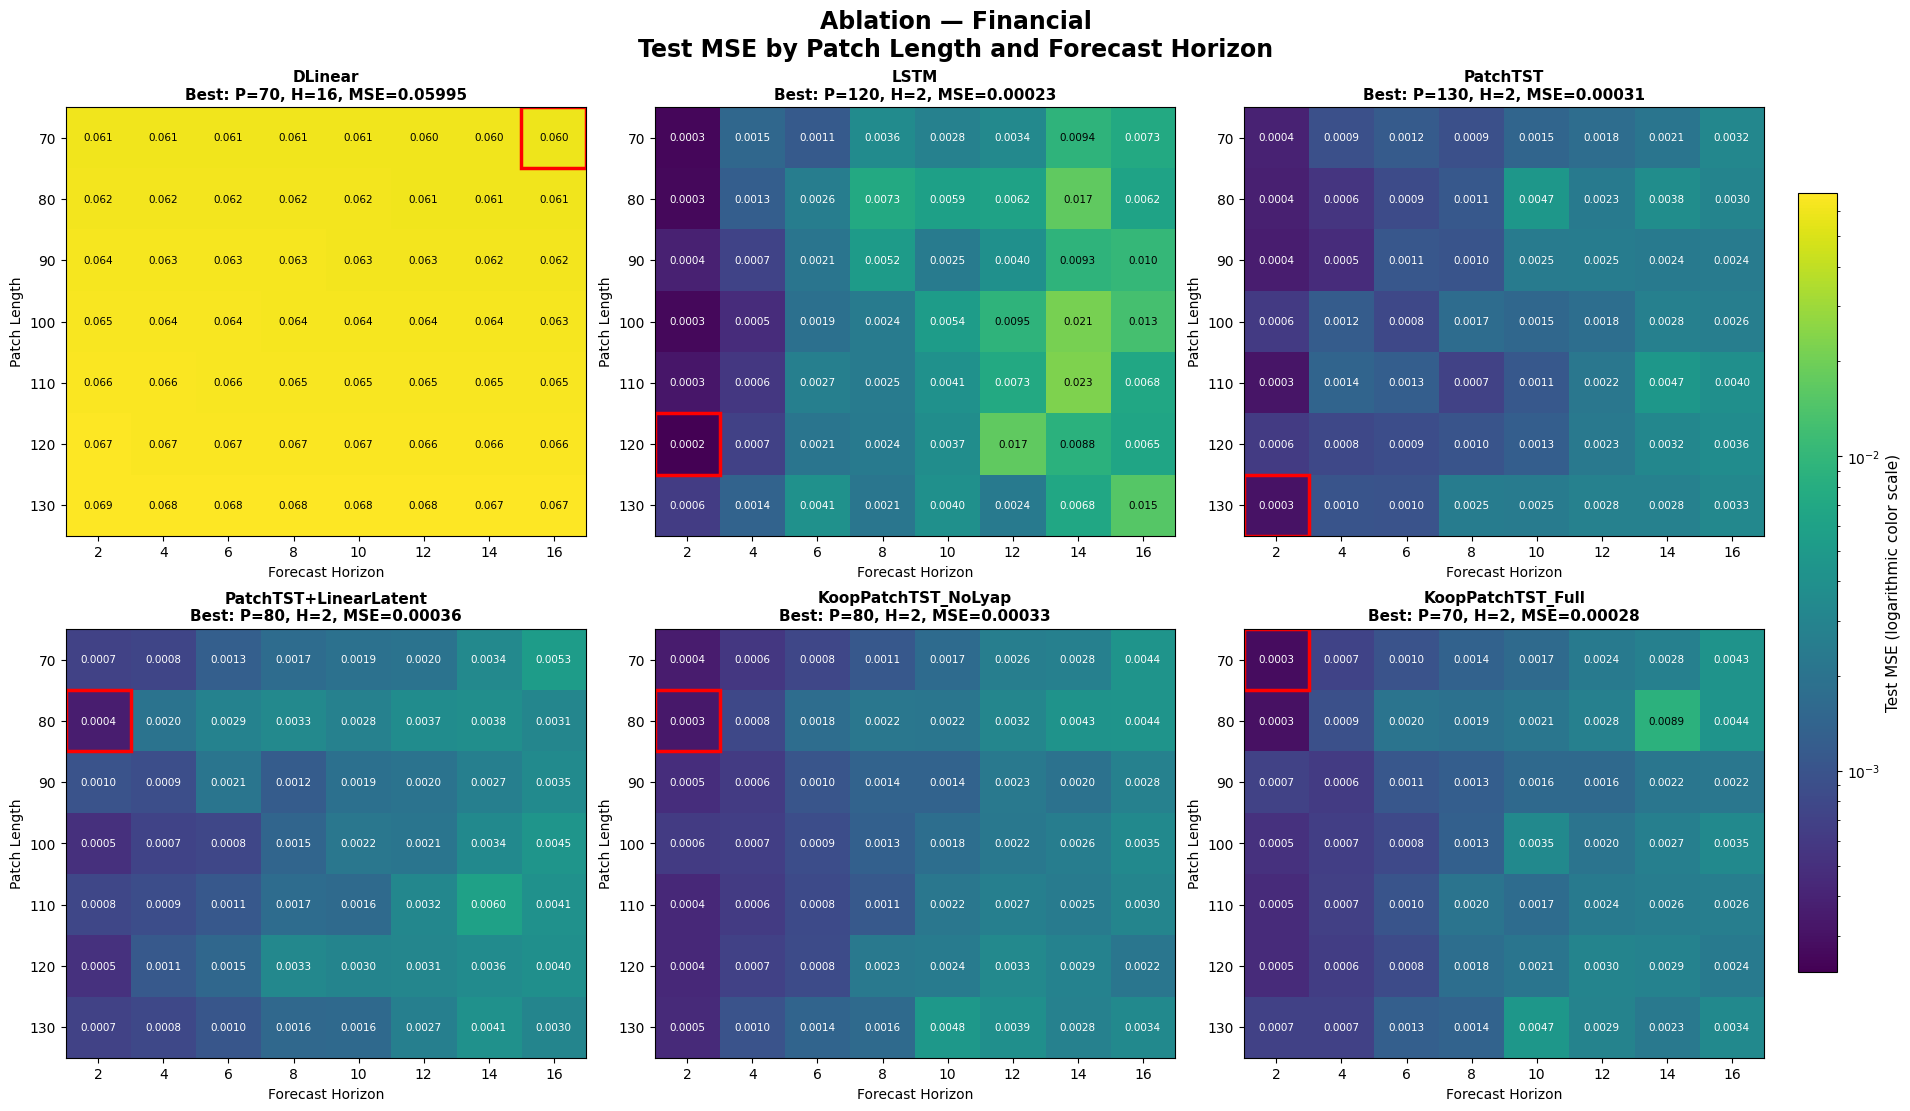

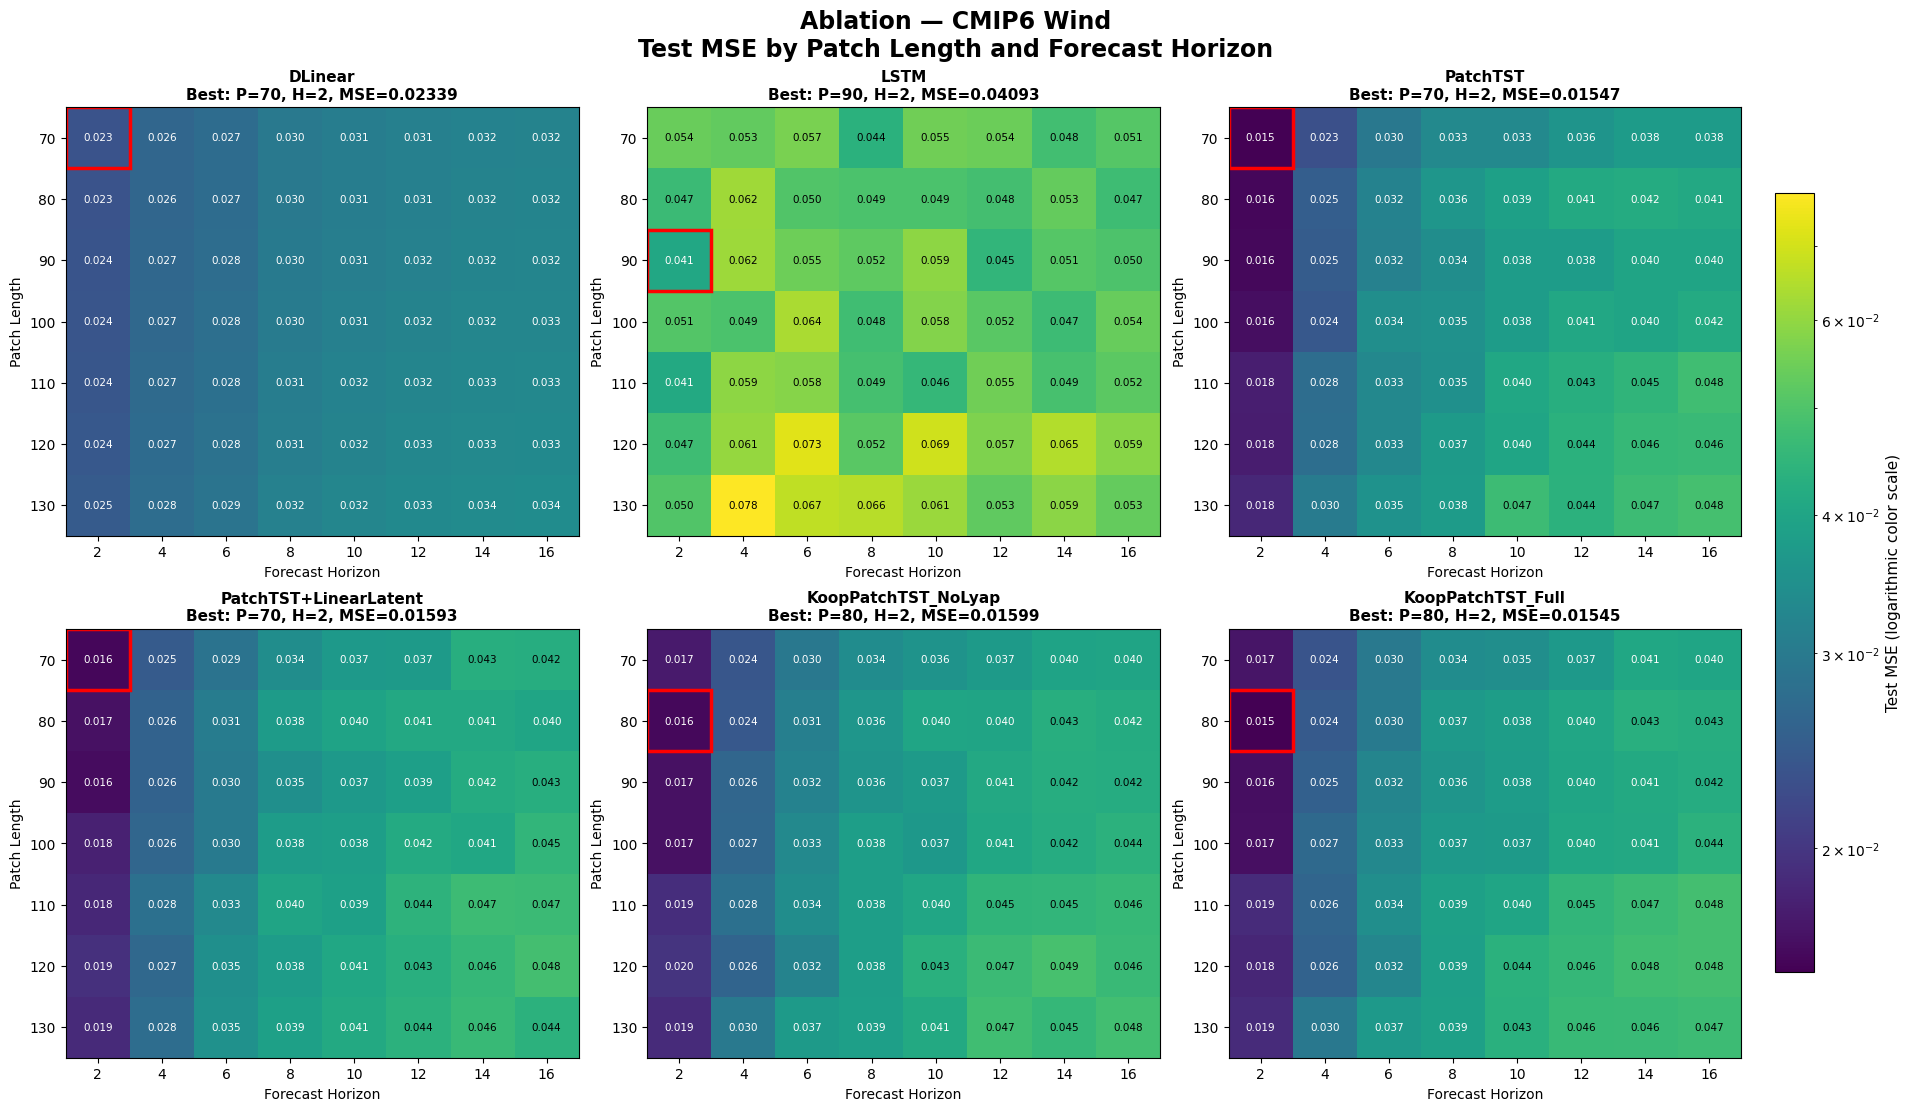

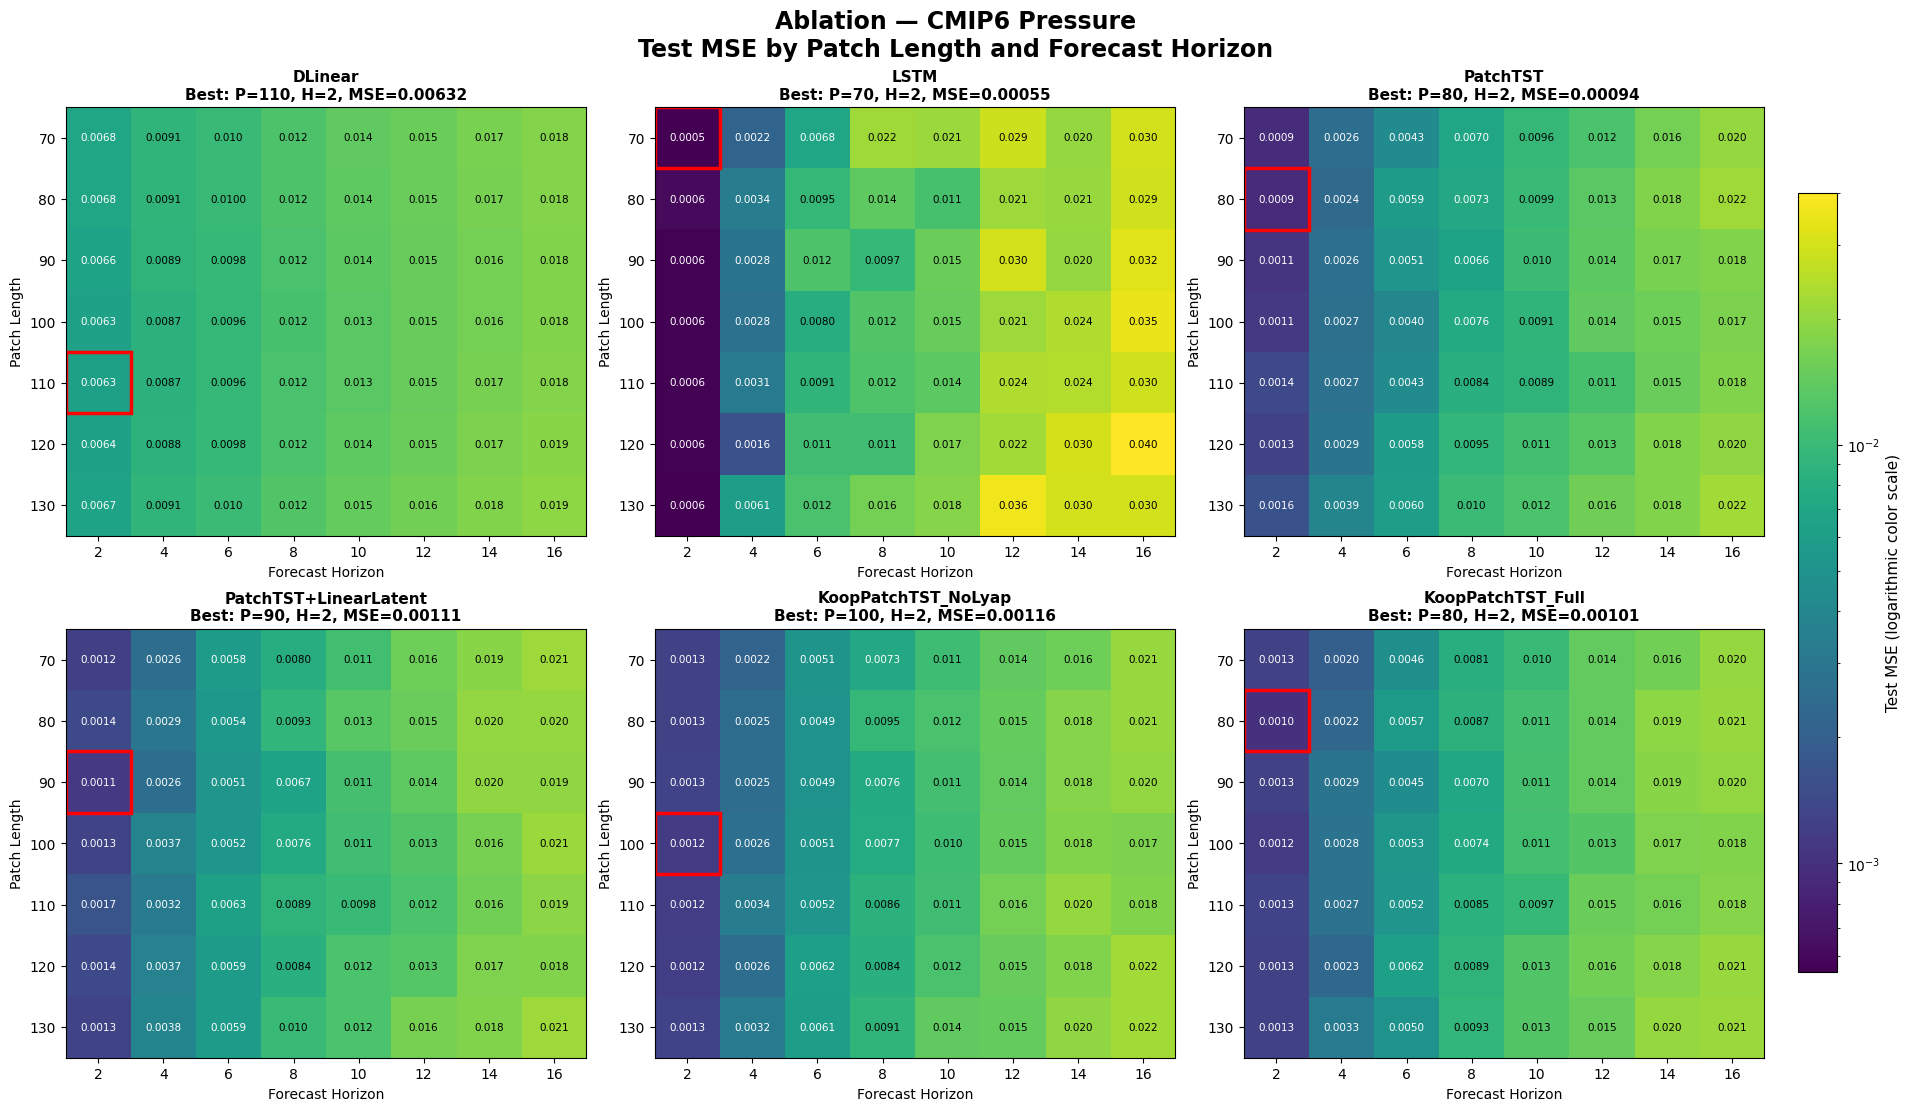


=== BEST PATCH / HORIZON CONFIGURATIONS ===


,Dataset,Model,Best_PatchLen,Best_Horizon,Best_MSE
0,Electricity,DLinear,100,2,0.038232
1,Electricity,LSTM,100,2,0.008489
2,Electricity,PatchTST,90,2,0.005551
3,Electricity,PatchTST+LinearLatent,70,2,0.006540
4,Electricity,KoopPatchTST_NoLyap,70,2,0.005250
5,Electricity,KoopPatchTST_Full,70,2,0.005583
6,Financial,DLinear,70,16,0.059953
7,Financial,LSTM,120,2,0.000229
8,Financial,PatchTST,130,2,0.000306
9,Financial,PatchTST+LinearLatent,80,2,0.000365


In [9]:
from matplotlib.colors import Normalize, LogNorm
from matplotlib.patches import Rectangle

FIG02_FILES = []
best_config_rows = []

# 1. Verify all combinations
assert len(test) == 1344

expected_grid = {
    (p, h)
    for p in PATCH_LENGTHS
    for h in HORIZONS
}

for dataset in DATASET_ORDER:

    dataset_df = test[
        test["Dataset"] == dataset
    ].copy()

    assert len(dataset_df) == 336

    # Shared color normalization across all 6 models
    values = dataset_df["MSE"].to_numpy()

    assert np.isfinite(values).all()
    assert (values > 0).all()

    vmin = float(values.min())
    vmax = float(values.max())

    use_log = (vmax / vmin) > 4

    if use_log:
        norm = LogNorm(vmin=vmin, vmax=vmax)
        scale_name = "logarithmic"
    else:
        norm = Normalize(vmin=vmin, vmax=vmax)
        scale_name = "linear"

    # 2 rows × 3 columns
    fig, axes = plt.subplots(
        2, 3,
        figsize=(19, 11),
        constrained_layout=True
    )

    fig.suptitle(
        f"Ablation — {dataset}\n"
        "Test MSE by Patch Length and Forecast Horizon",
        fontsize=17,
        fontweight="bold"
    )

    image = None

    for ax, model_name in zip(
        axes.flat, MODEL_ORDER
    ):

        subset = dataset_df[
            dataset_df["Model"] == model_name
        ]

        assert len(subset) == 56

        actual_grid = set(zip(
            subset["PatchLen"],
            subset["Horizon"]
        ))

        assert actual_grid == expected_grid

        # 7 × 8 MSE matrix
        matrix_df = (
            subset.pivot(
                index="PatchLen",
                columns="Horizon",
                values="MSE"
            )
            .reindex(
                index=PATCH_LENGTHS,
                columns=HORIZONS
            )
        )

        assert not matrix_df.isna().any().any()

        matrix = matrix_df.to_numpy(
            dtype=float
        )

        assert matrix.shape == (7, 8)

        image = ax.imshow(
            matrix,
            cmap="viridis",
            norm=norm,
            aspect="auto",
            origin="upper"
        )

        # Axis labels
        ax.set_xticks(range(len(HORIZONS)))
        ax.set_xticklabels(HORIZONS)

        ax.set_yticks(range(len(PATCH_LENGTHS)))
        ax.set_yticklabels(PATCH_LENGTHS)

        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("Patch Length")

        # Find best grid configuration
        best_pos = np.unravel_index(
            np.argmin(matrix),
            matrix.shape
        )

        best_row, best_col = best_pos

        best_p = PATCH_LENGTHS[best_row]
        best_h = HORIZONS[best_col]
        best_mse = float(matrix[best_pos])

        best_config_rows.append({
            "Dataset": dataset,
            "Model": model_name,
            "Best_PatchLen": best_p,
            "Best_Horizon": best_h,
            "Best_MSE": best_mse
        })

        ax.set_title(
            f"{model_name}\n"
            f"Best: P={best_p}, H={best_h}, "
            f"MSE={best_mse:.5f}",
            fontsize=11,
            fontweight="bold"
        )

        # Annotate MSE values
        for row in range(len(PATCH_LENGTHS)):
            for col in range(len(HORIZONS)):

                val = matrix[row, col]

                label = (
                    f"{val:.4f}"
                    if val < 0.01
                    else f"{val:.3f}"
                )

                # Select readable text color based
                # on the actual normalized color.
                rgba = image.cmap(
                    image.norm(val)
                )

                luminance = (
                    0.2126 * rgba[0]
                    + 0.7152 * rgba[1]
                    + 0.0722 * rgba[2]
                )

                text_color = (
                    "black" if luminance > 0.55
                    else "white"
                )

                ax.text(
                    col,
                    row,
                    label,
                    ha="center",
                    va="center",
                    fontsize=7.5,
                    color=text_color
                )

        # Highlight minimum MSE within the model
        ax.add_patch(
            Rectangle(
                (
                    best_col - 0.5,
                    best_row - 0.5
                ),
                1, 1,
                fill=False,
                edgecolor="red",
                linewidth=2.5
            )
        )

    # One shared colorbar for fair comparison
    colorbar = fig.colorbar(
        image,
        ax=axes.ravel().tolist(),
        shrink=0.82,
        pad=0.02
    )

    colorbar.set_label(
        f"Test MSE ({scale_name} color scale)",
        fontsize=11
    )

    # Save figure
    name = (
        "fig02_mse_heatmap_"
        + dataset.lower().replace(" ", "_")
        + ".png"
    )

    path = FIGURE_DIR / name

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    FIG02_FILES.append(path)

    plt.show()
    plt.close(fig)


# Summary of best configurations
BEST_CONFIG_DF = pd.DataFrame(
    best_config_rows
)

assert len(BEST_CONFIG_DF) == 24

print("\n=== BEST PATCH / HORIZON CONFIGURATIONS ===")

display(
    BEST_CONFIG_DF.round(6)
)

## 3. Paired Ablation Comparison

Phần này thực hiện so sánh từng cặp mô hình trên cùng dataset, patch length và forecast horizon.

Bốn phép so sánh được sử dụng:

1. PatchTST+LinearLatent so với PatchTST.
2. KoopPatchTST_NoLyap so với PatchTST+LinearLatent.
3. KoopPatchTST_Full so với KoopPatchTST_NoLyap.
4. KoopPatchTST_Full so với PatchTST.

Sự thay đổi tương đối của Test MSE được tính theo công thức:

`MSE Change (%) = 100 × (MSE_new - MSE_baseline) / MSE_baseline`

Giá trị âm biểu thị mô hình mới có MSE thấp hơn baseline, trong khi giá trị dương biểu thị MSE cao hơn.

Biểu đồ heatmap sử dụng thang màu phân kỳ với tâm tại 0 để minh họa sự cải thiện hoặc suy giảm hiệu năng.

Các phép so sánh giúp phân tích riêng tác động của latent propagation, ràng buộc ổn định Koopman và chính quy hóa Lyapunov.

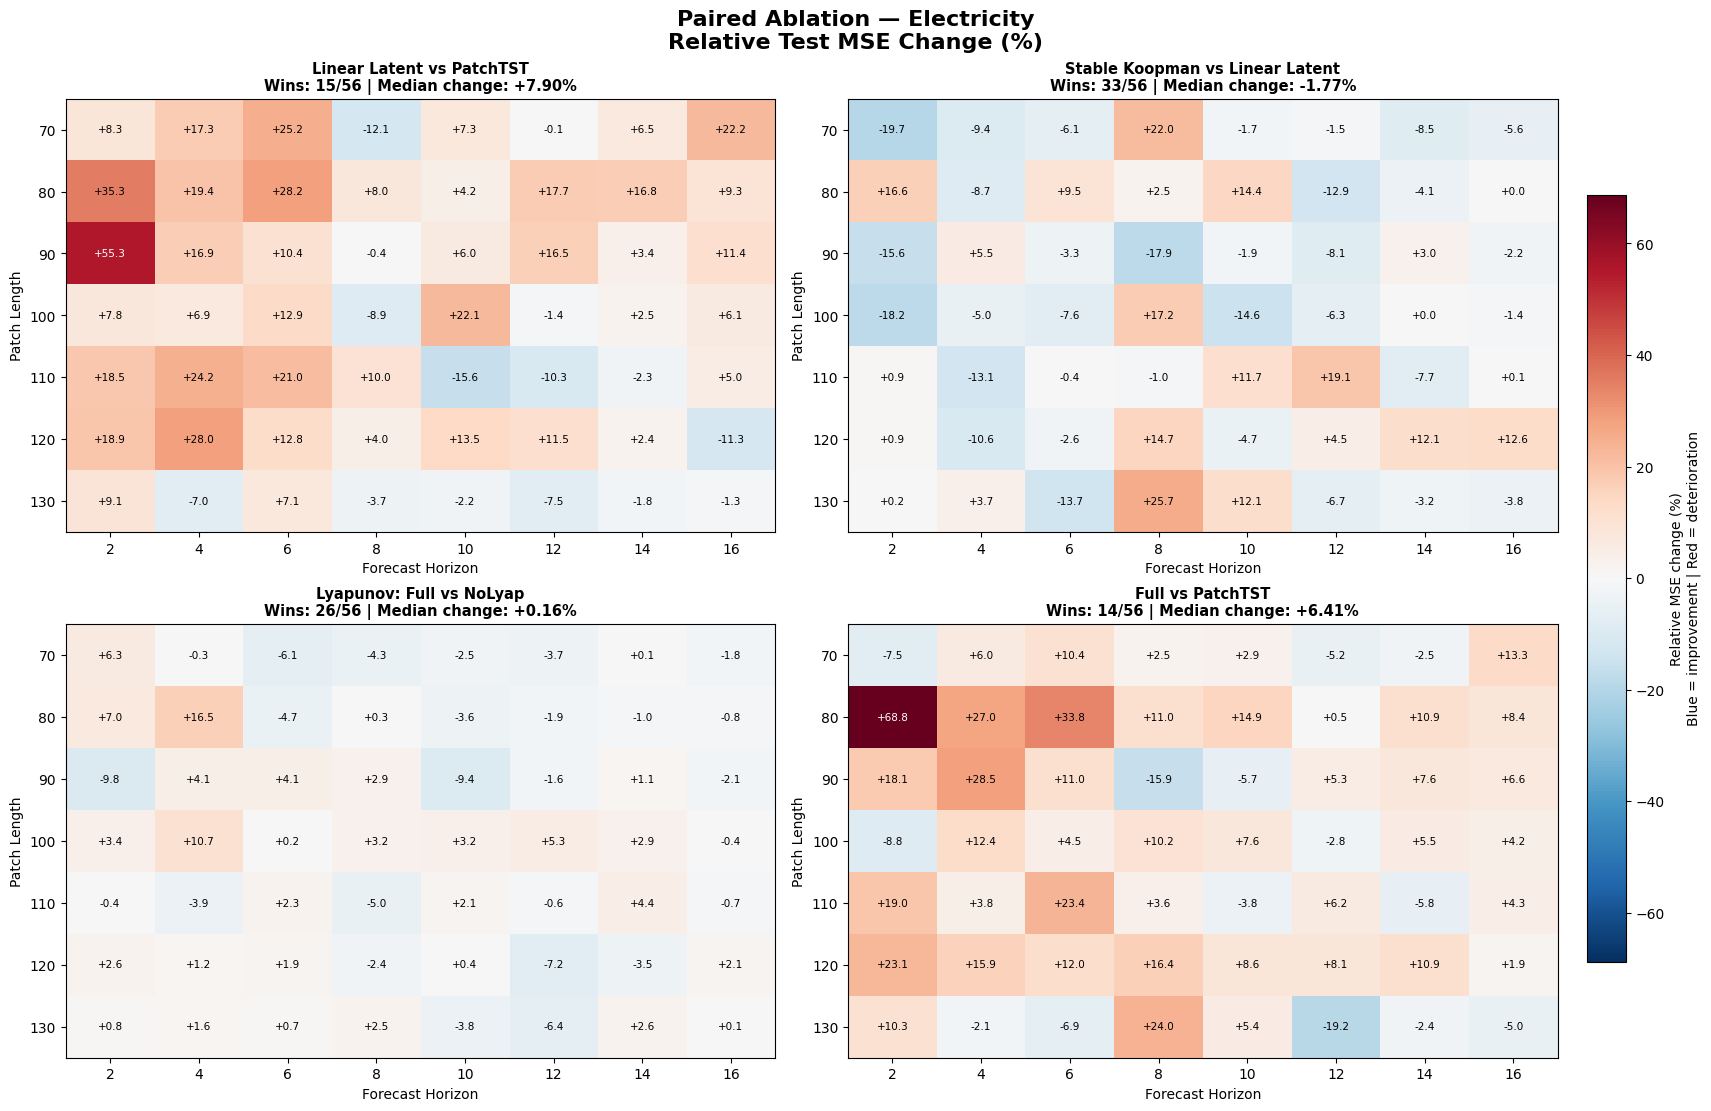

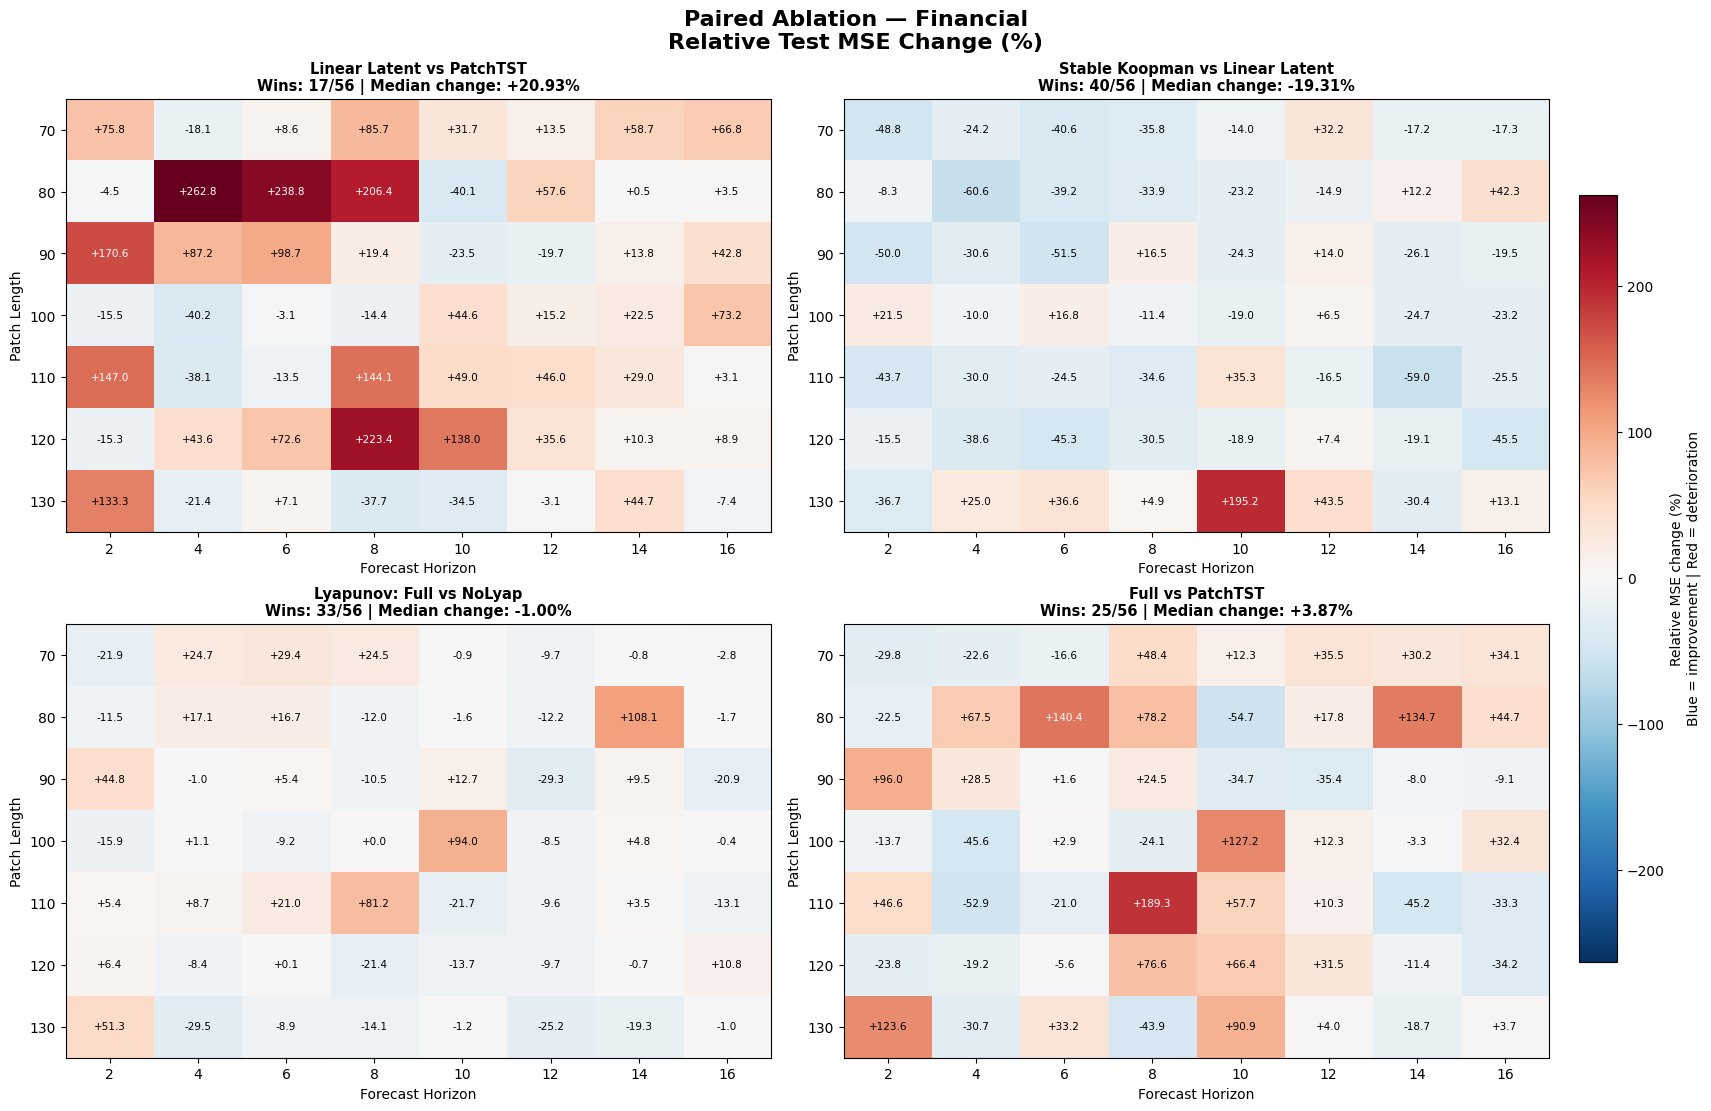

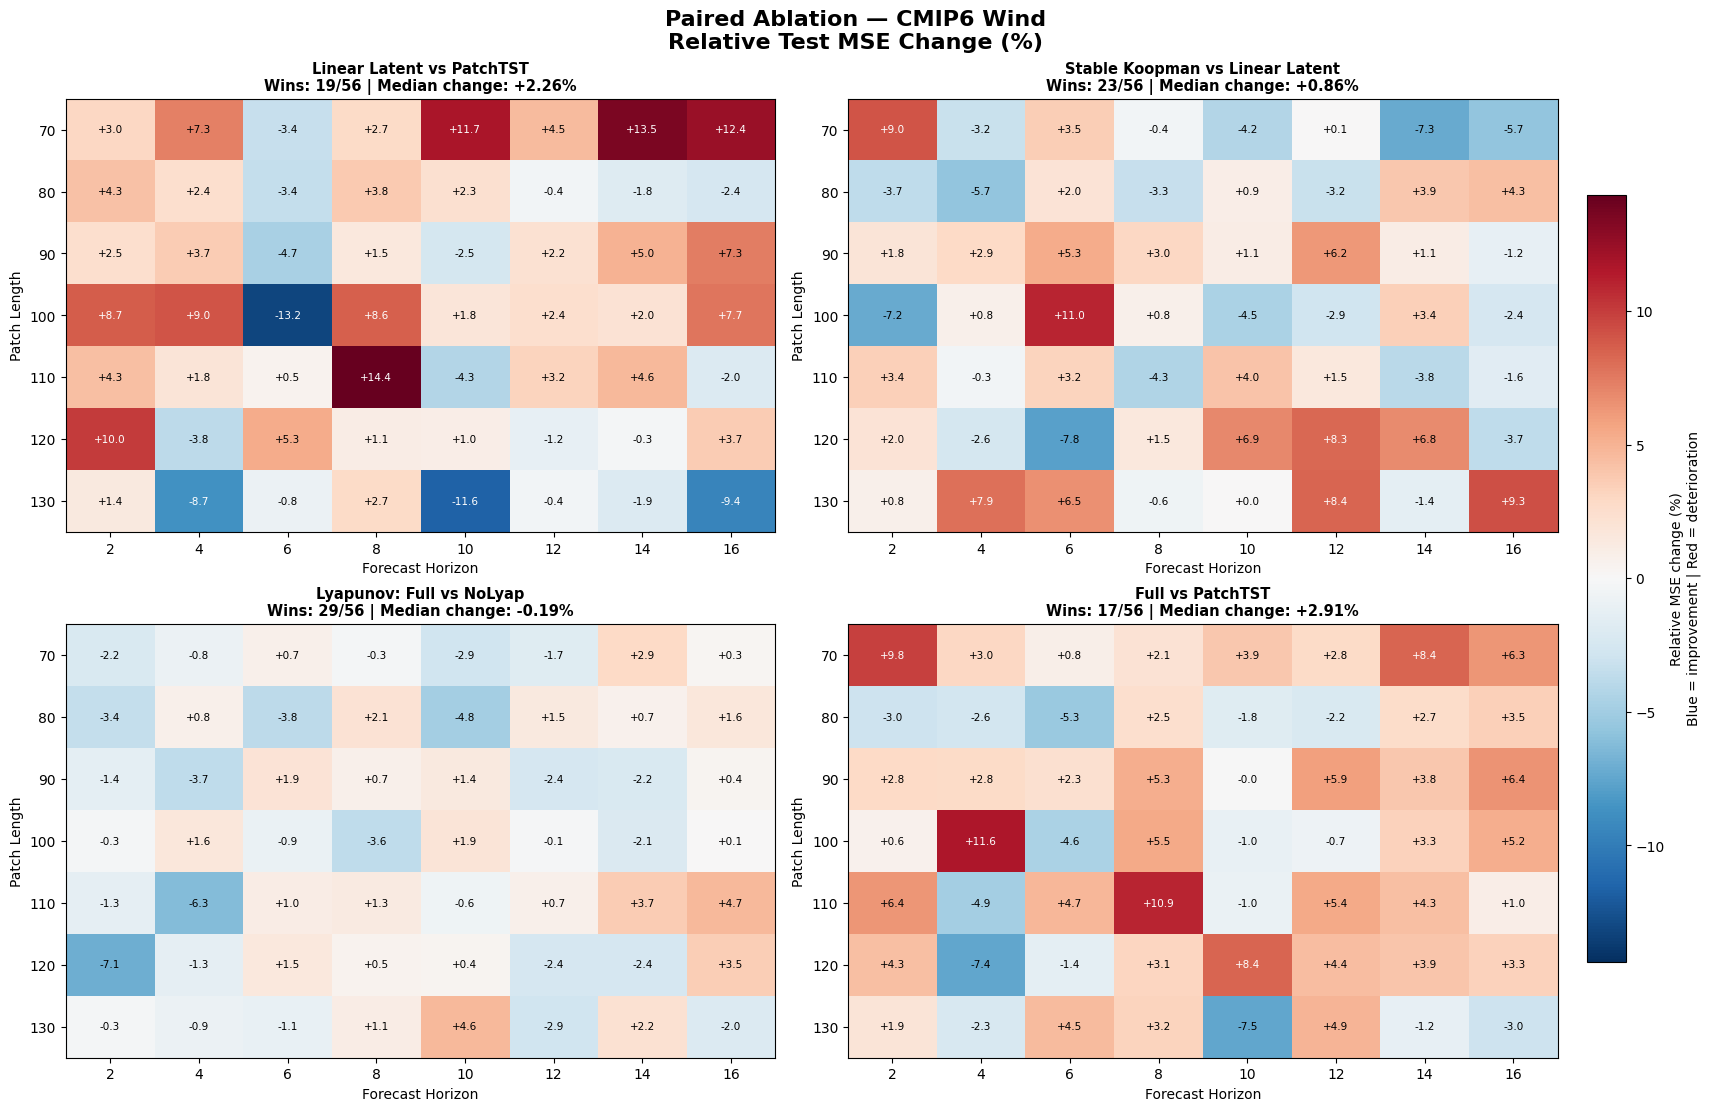

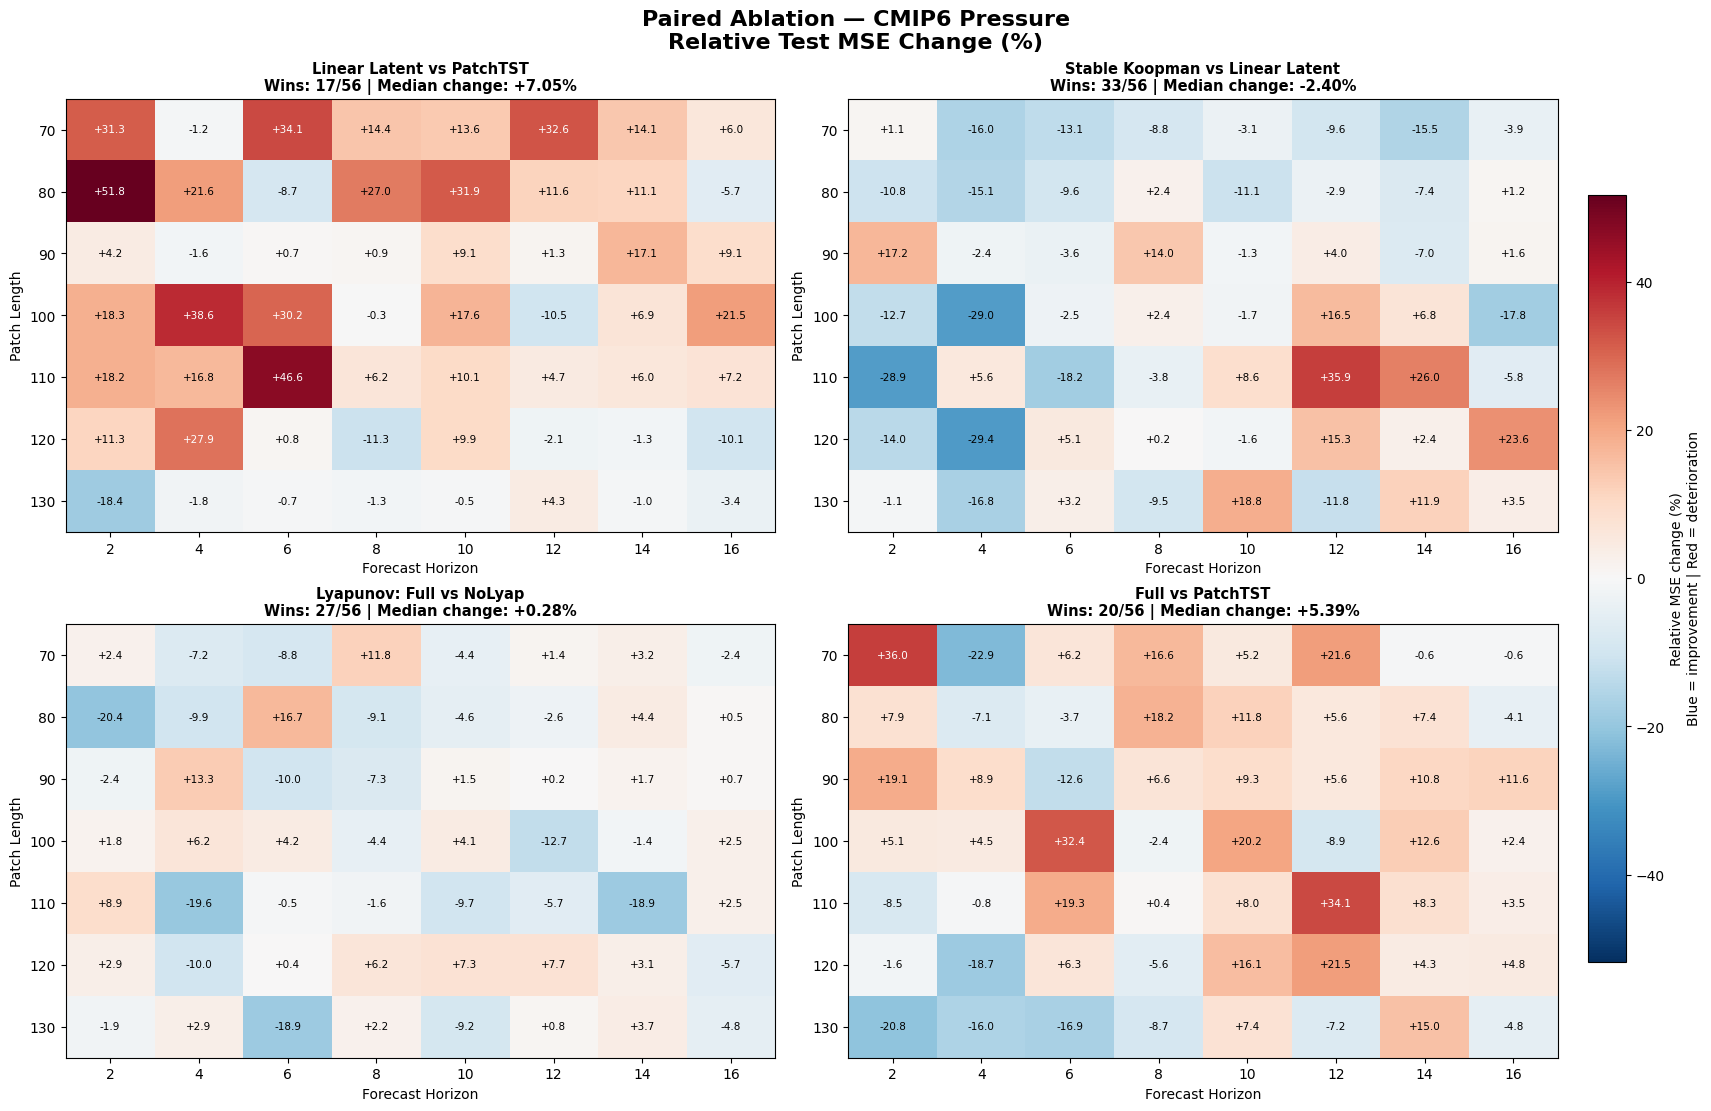


=== PAIRED ABLATION SUMMARY ===


,Dataset,Comparison,Wins,Losses,Ties,Win_Rate_Pct,Mean_Pct_Change,Median_Pct_Change,Pct_Change_of_Mean_MSE
0,CMIP6 Pressure,Linear Latent vs PatchTST,17,39,0,30.3571,10.1189,7.0518,6.8658
1,CMIP6 Wind,Linear Latent vs PatchTST,19,37,0,33.9286,1.9310,2.2590,1.5232
2,Electricity,Linear Latent vs PatchTST,15,41,0,26.7857,8.9986,7.9043,6.3583
3,Financial,Linear Latent vs PatchTST,17,39,0,30.3571,44.3574,20.9327,25.2163
4,CMIP6 Pressure,Stable Koopman vs Linear Latent,33,23,0,58.9286,-2.1149,-2.4050,0.0774
5,CMIP6 Wind,Stable Koopman vs Linear Latent,23,33,0,41.0714,0.9010,0.8584,0.8490
6,Electricity,Stable Koopman vs Linear Latent,33,23,0,58.9286,-0.6922,-1.7706,-0.5739
7,Financial,Stable Koopman vs Linear Latent,40,16,0,71.4286,-11.7748,-19.3121,-14.6001
8,CMIP6 Pressure,Lyapunov: Full vs NoLyap,27,29,0,48.2143,-1.5837,0.2771,-1.4967
9,CMIP6 Wind,Lyapunov: Full vs NoLyap,29,27,0,51.7857,-0.3836,-0.1911,-0.1869


In [ ]:
from matplotlib.colors import TwoSlopeNorm


PAIR_COMPARISONS = [
    (
        "Linear Latent vs PatchTST",
        "PatchTST",
        "PatchTST+LinearLatent"
    ),
    (
        "Stable Koopman vs Linear Latent",
        "PatchTST+LinearLatent",
        "KoopPatchTST_NoLyap"
    ),
    (
        "Lyapunov: Full vs NoLyap",
        "KoopPatchTST_NoLyap",
        "KoopPatchTST_Full"
    ),
    (
        "Full vs PatchTST",
        "PatchTST",
        "KoopPatchTST_Full"
    )
]

# 2. Load the consolidated experiment
METRICS_PATH = RESULTS_DIR / "metrics.csv"

metrics = pd.read_csv(METRICS_PATH)

test = metrics[
    metrics["Set"].astype(str).str.lower() == "test"
].copy()

KEYS = ["Dataset", "PatchLen", "Horizon"]

assert len(test) == 1344
assert not test.duplicated(KEYS + ["Model"]).any()
assert np.isfinite(test["MSE"]).all()
assert (test["MSE"] > 0).all()

# 3. Create matched comparison matrix
wide = test.pivot(
    index=KEYS,
    columns="Model",
    values="MSE"
)

assert wide.shape == (224, 6)
assert not wide.isna().any().any()

# 4. Calculate paired MSE differences
PAIR_ROWS = []

for comparison_name, baseline, treatment in PAIR_COMPARISONS:

    for (dataset, patch, horizon), row in wide.iterrows():

        mse_base = float(row[baseline])
        mse_new = float(row[treatment])

        diff = mse_new - mse_base
        pct = 100.0 * diff / mse_base

        PAIR_ROWS.append({
            "Dataset": dataset,
            "PatchLen": patch,
            "Horizon": horizon,
            "Comparison": comparison_name,
            "Baseline": baseline,
            "Treatment": treatment,
            "Baseline_MSE": mse_base,
            "Treatment_MSE": mse_new,
            "MSE_Difference": diff,
            "MSE_Change_Pct": pct,
            "Improved": diff < -1e-12
        })

PAIR_DF = pd.DataFrame(PAIR_ROWS)

assert len(PAIR_DF) == 896
assert np.isfinite(
    PAIR_DF["MSE_Change_Pct"]
).all()

# 5. Aggregate paired comparisons
SUMMARY_ROWS = []

for (dataset, comparison), group in PAIR_DF.groupby(
    ["Dataset", "Comparison"],
    sort=False
):

    assert len(group) == 56

    diff = group["MSE_Difference"].to_numpy()
    pct = group["MSE_Change_Pct"].to_numpy()

    wins = int(np.sum(diff < -1e-12))
    losses = int(np.sum(diff > 1e-12))
    ties = len(group) - wins - losses

    SUMMARY_ROWS.append({
        "Dataset": dataset,
        "Comparison": comparison,
        "Baseline": group["Baseline"].iloc[0],
        "Treatment": group["Treatment"].iloc[0],
        "Configurations": len(group),
        "Wins": wins,
        "Losses": losses,
        "Ties": ties,
        "Win_Rate_Pct": 100 * wins / len(group),
        "Mean_MSE_Diff": float(diff.mean()),
        "Mean_Pct_Change": float(pct.mean()),
        "Median_Pct_Change": float(np.median(pct)),
        "Pct_Change_of_Mean_MSE": float(
            100 * (
                group["Treatment_MSE"].mean()
                / group["Baseline_MSE"].mean()
                - 1
            )
        )
    })

PAIR_SUMMARY = pd.DataFrame(SUMMARY_ROWS)

assert len(PAIR_SUMMARY) == 16
assert (PAIR_SUMMARY["Configurations"] == 56).all()


# 7. Visualize paired improvements
FIG03_FILES = []

for dataset in DATASET_ORDER:

    dataset_pairs = PAIR_DF[
        PAIR_DF["Dataset"] == dataset
    ]

    assert len(dataset_pairs) == 4 * 56

    # Same color range for all four comparisons
    color_limit = max(
        0.1,
        float(
            dataset_pairs["MSE_Change_Pct"]
            .abs().max()
        )
    )

    norm = TwoSlopeNorm(
        vmin=-color_limit,
        vcenter=0,
        vmax=color_limit
    )

    fig, axes = plt.subplots(
        2, 2,
        figsize=(17, 11),
        constrained_layout=True
    )

    fig.suptitle(
        f"Paired Ablation — {dataset}\n"
        "Relative Test MSE Change (%)",
        fontsize=16,
        fontweight="bold"
    )

    image = None

    for ax, (name, baseline, treatment) in zip(
        axes.flat, PAIR_COMPARISONS
    ):

        subset = dataset_pairs[
            dataset_pairs["Comparison"] == name
        ]

        matrix_df = subset.pivot(
            index="PatchLen",
            columns="Horizon",
            values="MSE_Change_Pct"
        ).reindex(
            index=PATCH_LENGTHS,
            columns=HORIZONS
        )

        assert matrix_df.shape == (7, 8)
        assert not matrix_df.isna().any().any()

        matrix = matrix_df.to_numpy()

        image = ax.imshow(
            matrix,
            cmap="RdBu_r",
            norm=norm,
            aspect="auto"
        )

        ax.set_xticks(range(len(HORIZONS)))
        ax.set_xticklabels(HORIZONS)

        ax.set_yticks(range(len(PATCH_LENGTHS)))
        ax.set_yticklabels(PATCH_LENGTHS)

        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("Patch Length")

        wins = int(
            (subset["MSE_Difference"] < -1e-12).sum()
        )

        median_change = float(
            subset["MSE_Change_Pct"].median()
        )

        ax.set_title(
            f"{name}\n"
            f"Wins: {wins}/56 | "
            f"Median change: {median_change:+.2f}%",
            fontsize=10.5,
            fontweight="bold"
        )

        # Annotate each matched configuration
        for i in range(len(PATCH_LENGTHS)):
            for j in range(len(HORIZONS)):

                value = matrix[i, j]

                color = image.cmap(
                    image.norm(value)
                )

                luminance = (
                    0.2126 * color[0]
                    + 0.7152 * color[1]
                    + 0.0722 * color[2]
                )

                ax.text(
                    j, i,
                    f"{value:+.1f}",
                    ha="center",
                    va="center",
                    fontsize=7.5,
                    color=(
                        "black"
                        if luminance > 0.55
                        else "white"
                    )
                )

    colorbar = fig.colorbar(
        image,
        ax=axes.ravel().tolist(),
        shrink=0.80,
        pad=0.02
    )

    colorbar.set_label(
        "Relative MSE change (%)\n"
        "Blue = improvement | Red = deterioration"
    )

    filename = (
        "fig03_paired_ablation_"
        + dataset.lower().replace(" ", "_")
        + ".png"
    )

    path = FIGURE_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    FIG03_FILES.append(path)

    plt.show()
    plt.close(fig)

# 8. Final report
print("\n=== PAIRED ABLATION SUMMARY ===")

display(
    PAIR_SUMMARY[[
        "Dataset",
        "Comparison",
        "Wins",
        "Losses",
        "Ties",
        "Win_Rate_Pct",
        "Mean_Pct_Change",
        "Median_Pct_Change",
        "Pct_Change_of_Mean_MSE"
    ]].round(4)
)

## 4. Model Win Rate Analysis

Phần này đánh giá tần suất mỗi mô hình đạt Test MSE thấp nhất trong các cấu hình thực nghiệm.

Với mỗi dataset, 56 cặp patch length và forecast horizon được xét độc lập.

Ở mỗi cấu hình, mô hình có Test MSE nhỏ nhất được xác định là mô hình chiến thắng.

Các trường hợp bằng nhau tuyệt đối được xử lý bằng cách sắp xếp theo tên mô hình để lựa chọn kết quả một cách xác định.

Win Rate được tính bằng tỷ lệ số cấu hình chiến thắng trên tổng số 56 cấu hình của dataset.

Phân tích cho phép đánh giá mức độ cạnh tranh của các mô hình trên toàn bộ grid thay vì chỉ dựa vào MSE trung bình.

Configurations with exact MSE ties: 0


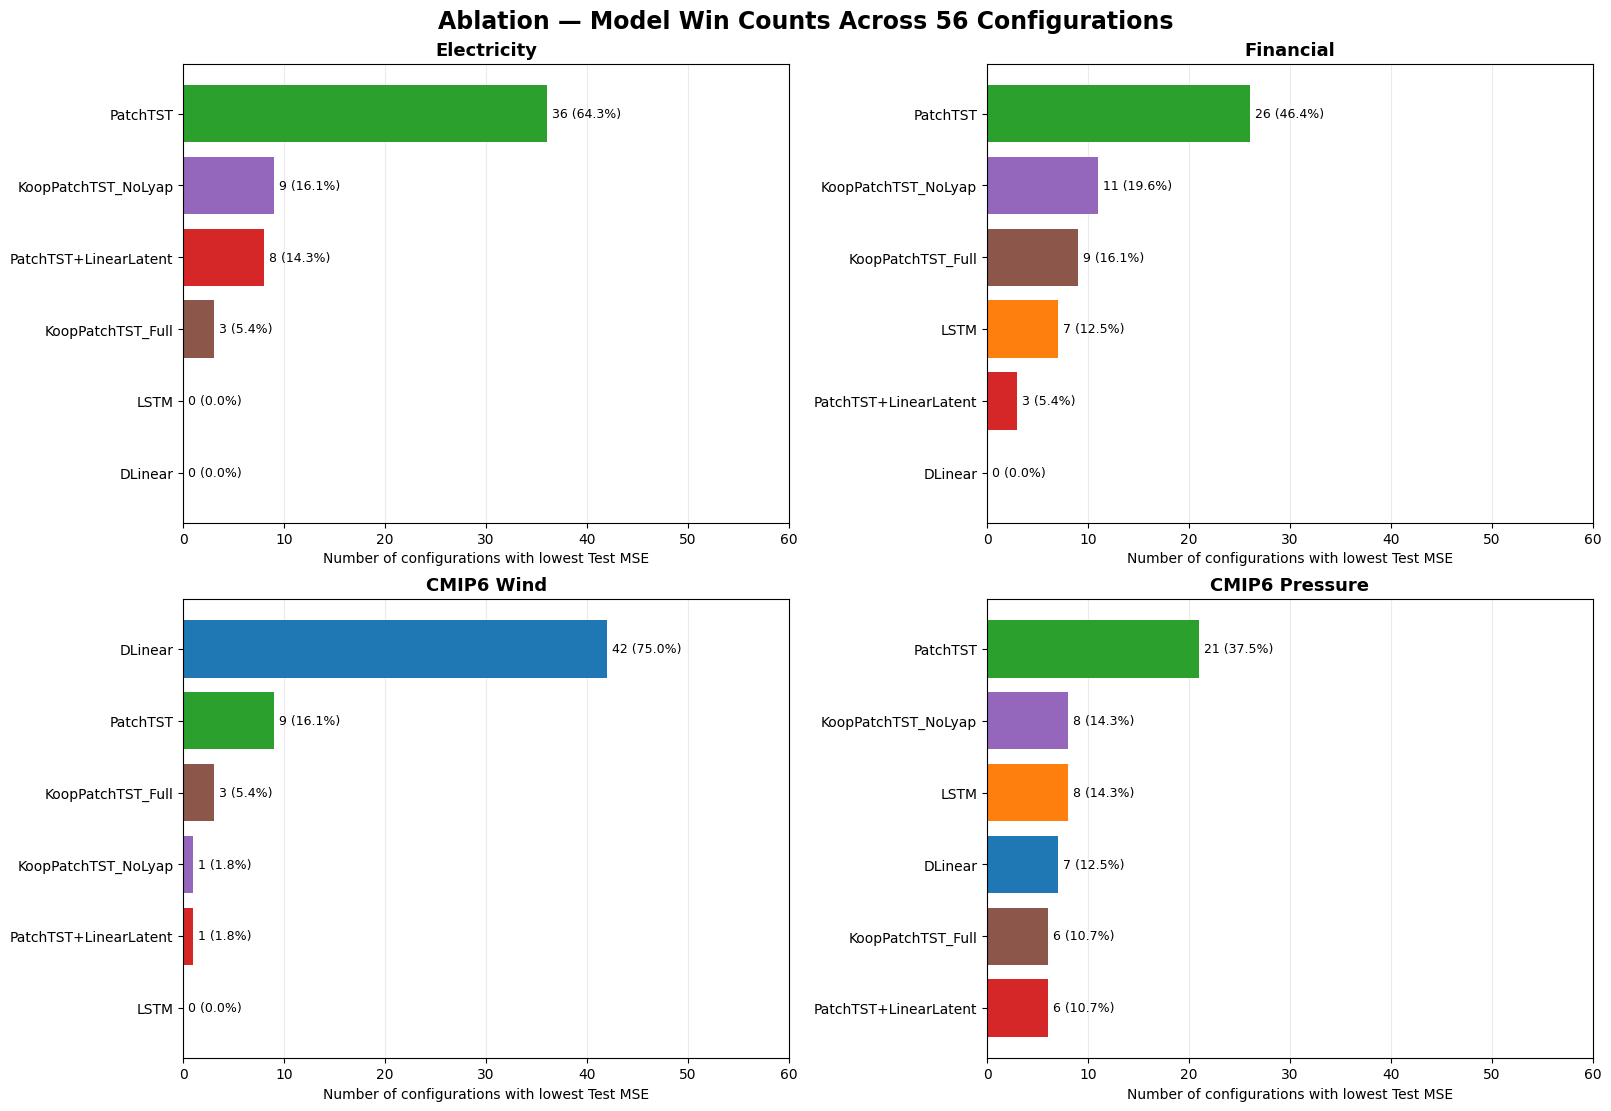


=== MODEL WIN COUNTS ===


Model,DLinear,LSTM,PatchTST,PatchTST+LinearLatent,KoopPatchTST_NoLyap,KoopPatchTST_Full
Dataset,,,,,,
Electricity,0,0,36,8,9,3
Financial,0,7,26,3,11,9
CMIP6 Wind,42,0,9,1,1,3
CMIP6 Pressure,7,8,21,6,8,6



=== MODEL WIN RATES (%) ===


Model,DLinear,LSTM,PatchTST,PatchTST+LinearLatent,KoopPatchTST_NoLyap,KoopPatchTST_Full
Dataset,,,,,,
Electricity,0.0,0.00,64.29,14.29,16.07,5.36
Financial,0.0,12.50,46.43,5.36,19.64,16.07
CMIP6 Wind,75.0,0.00,16.07,1.79,1.79,5.36
CMIP6 Pressure,12.5,14.29,37.50,10.71,14.29,10.71



=== OVERALL WIN COUNTS ===


,Wins,Win_Rate_Pct
Model,,
PatchTST,92,41.07
DLinear,49,21.88
KoopPatchTST_NoLyap,29,12.95
KoopPatchTST_Full,21,9.38
PatchTST+LinearLatent,18,8.04
LSTM,15,6.70


In [10]:
# 1. Load consolidated metrics
df = pd.read_csv(
    RESULTS_DIR / "metrics.csv"
)

test = df[
    df["Set"].astype(str).str.lower() == "test"
].copy()

KEYS = [
    "Dataset",
    "PatchLen",
    "Horizon"
]

assert len(test) == 1344
assert not test.duplicated(
    KEYS + ["Model"]
).any()

# 2. Select minimum MSE at each configuration
# If exact ties occur, sort by model name
# for deterministic selection.
winners = (
    test.sort_values(
        KEYS + ["MSE", "Model"]
    )
    .drop_duplicates(KEYS)
    .copy()
)

assert len(winners) == 224

# Count exact ties separately
tie_counts = (
    test.groupby(KEYS)["MSE"]
    .apply(lambda s: (s == s.min()).sum())
)

print(
    "Configurations with exact MSE ties:",
    int((tie_counts > 1).sum())
)

# 3. Calculate win counts
win_counts = (
    winners.groupby(
        ["Dataset", "Model"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=DATASET_ORDER,
        columns=MODEL_ORDER,
        fill_value=0
    )
)

assert win_counts.shape == (4, 6)
assert (win_counts.sum(axis=1) == 56).all()

win_rates = win_counts / 56 * 100

# 5. Plot all datasets
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

fig.suptitle(
    "Ablation — Model Win Counts Across 56 Configurations",
    fontsize=17,
    fontweight="bold"
)

palette = (
    plt.rcParams["axes.prop_cycle"]
    .by_key()["color"]
)

model_colors = {
    model: palette[i % len(palette)]
    for i, model in enumerate(MODEL_ORDER)
}

for ax, dataset in zip(
    axes.flat, DATASET_ORDER
):

    counts = (
        win_counts.loc[dataset]
        .sort_values(ascending=True)
    )

    models = counts.index.tolist()
    values = counts.to_numpy()

    bars = ax.barh(
        models,
        values,
        color=[
            model_colors[model]
            for model in models
        ]
    )

    ax.set_xlim(0, 60)
    ax.set_xlabel(
        "Number of configurations with lowest Test MSE"
    )

    ax.set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for bar, count in zip(bars, values):

        ax.text(
            bar.get_width() + 0.5,
            bar.get_y() + bar.get_height()/2,
            f"{count} ({count/56*100:.1f}%)",
            va="center",
            fontsize=9
        )

# 6. Save
FIG04_PATH = (
    FIGURE_DIR
    / "fig04_model_win_rate.png"
)

fig.savefig(
    FIG04_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 7. Report
print("\n=== MODEL WIN COUNTS ===")
display(win_counts)

print("\n=== MODEL WIN RATES (%) ===")
display(win_rates.round(2))

print("\n=== OVERALL WIN COUNTS ===")
overall = (
    win_counts.sum(axis=0)
    .sort_values(ascending=False)
)

display(pd.DataFrame({
    "Wins": overall,
    "Win_Rate_Pct": overall / 224 * 100
}).round(2))


## 5. Lyapunov Regularization and Koopman Stability

Phần này phân tích động thái huấn luyện của hai biến thể:

- KoopPatchTST_NoLyap
- KoopPatchTST_Full

Phân tích sử dụng training history được lưu từ các thực nghiệm đã hoàn thành, không tải lại mô hình để huấn luyện.

### Lyapunov Audit

Kiểm tra lịch sử weighted Lyapunov loss và spectral proxy của 224 cấu hình KoopPatchTST_Full.

### Training Dynamics Visualization

Lựa chọn cấu hình đại diện P=100, H=8, Seed=7 để trực quan hóa ba thành phần:

1. Training MSE theo epoch.
2. Weighted Lyapunov loss theo epoch.
3. Koopman spectral proxy theo epoch.

Biểu đồ giúp quan sát sự hội tụ của mô hình, sự xuất hiện của thành phần phạt Lyapunov và diễn biến của chỉ số theo dõi toán tử Koopman.

Lưu ý: Spectral proxy được ghi trong training history là chỉ số dựa trên tham số singular-value của toán tử, không đồng nghĩa trực tiếp với spectral radius thực tế.

=== LYAPUNOV AUDIT — ALL FULL RUNS ===


,Dataset,Runs,Runs_With_Nonzero_Lyap,Total_Nonzero_Epochs,Max_Weighted_Lyap,Max_Spectral_Proxy
0,CMIP6 Pressure,56,0,0,0.0,0.969816
1,CMIP6 Wind,56,0,0,0.0,0.969788
2,Electricity,56,0,0,0.0,0.942110
3,Financial,56,0,0,0.0,0.975048


Total Full runs with nonzero Lyapunov penalty: 0 /224


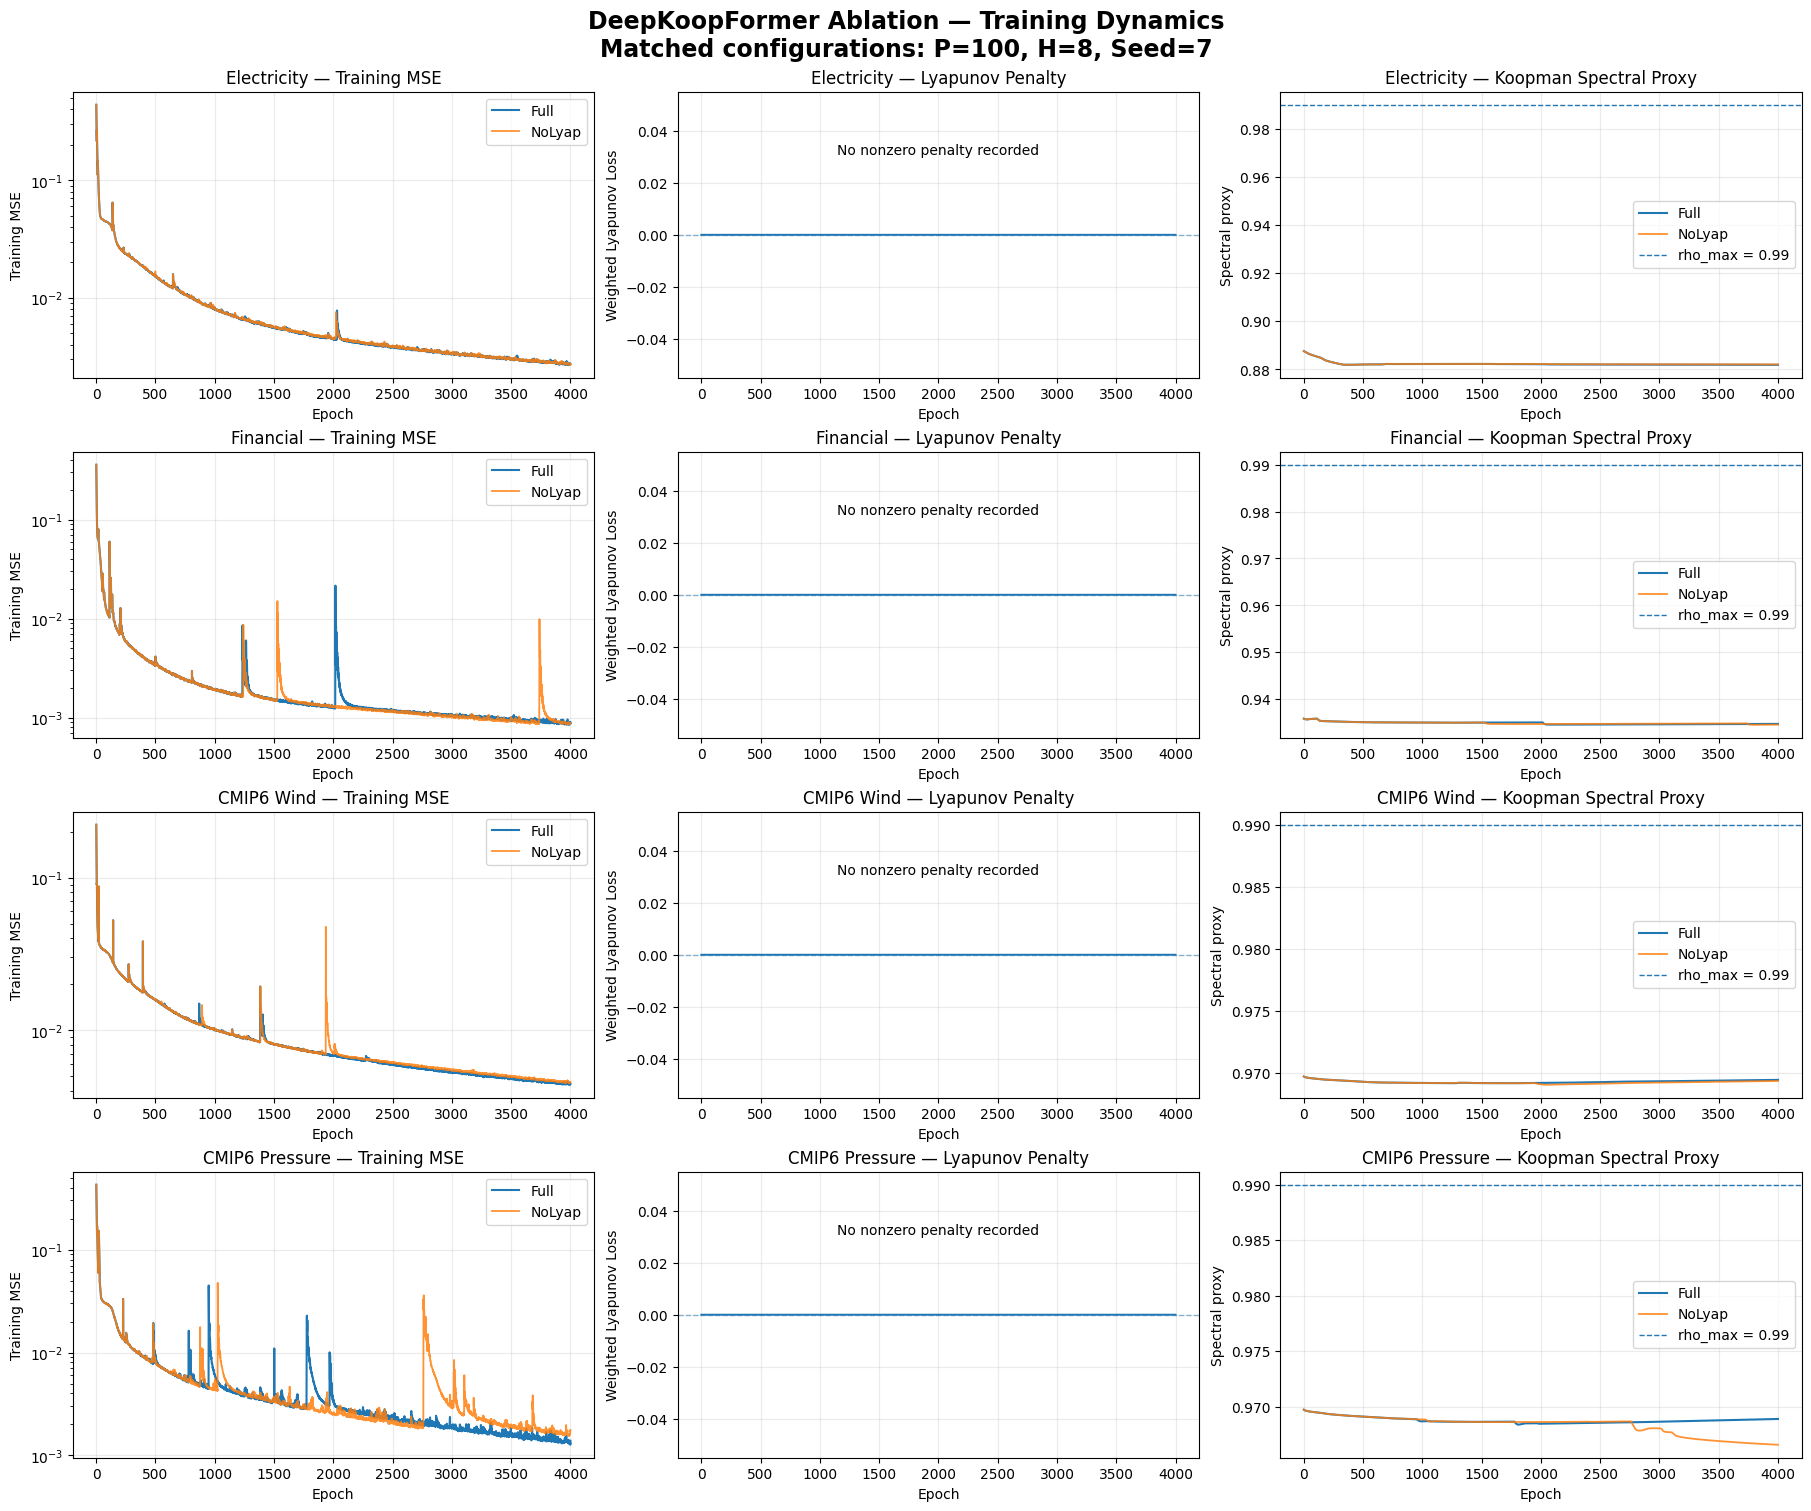

In [ ]:
DATASET_SLUGS = {
    "Electricity": "electricity",
    "Financial": "financial",
    "CMIP6 Wind": "cmip6_wind",
    "CMIP6 Pressure": "cmip6_pressure"
}

MODEL_SLUGS = {
    "Full": "kooppatchtst_full",
    "NoLyap": "kooppatchtst_nolyap"
}

REQUIRED_COLUMNS = {
    "epoch",
    "loss",
    "mse",
    "lyap_weighted",
    "spectral_proxy"
}

def load_history(dataset, model, p, h):

    path = (
        RESULTS_DIR
        / "ablation_runs"
        / DATASET_SLUGS[dataset]
        / f"p{p}_h{h}"
        / MODEL_SLUGS[model]
        / "e4000_seed7"
        / "training_history.csv"
    )

    if not path.is_file():
        raise FileNotFoundError(path)

    history = pd.read_csv(path)

    missing = REQUIRED_COLUMNS - set(history.columns)

    assert not missing, (
        f"{path}: missing columns {missing}"
    )

    assert len(history) == 4000
    assert history["epoch"].iloc[0] == 1
    assert history["epoch"].iloc[-1] == 4000

    numeric = history[
        ["loss", "mse", "lyap_weighted", "spectral_proxy"]
    ].to_numpy(dtype=float)

    assert np.isfinite(numeric).all()

    return history


# 1. Audit all 224 Full model runs

audit_rows = []

for dataset in DATASET_SLUGS:

    for p in PATCHES:
        for h in HORIZONS:

            history = load_history(
                dataset, "Full", p, h
            )

            lyap = history[
                "lyap_weighted"
            ].to_numpy(dtype=float)

            proxy = history[
                "spectral_proxy"
            ].to_numpy(dtype=float)

            audit_rows.append({
                "Dataset": dataset,
                "PatchLen": p,
                "Horizon": h,
                "Max_Abs_Weighted_Lyap": np.max(
                    np.abs(lyap)
                ),
                "Nonzero_Lyap_Epochs": int(
                    np.sum(np.abs(lyap) > 1e-12)
                ),
                "Max_Spectral_Proxy": float(
                    proxy.max()
                ),
                "Final_Spectral_Proxy": float(
                    proxy[-1]
                )
            })

LYAP_AUDIT = pd.DataFrame(audit_rows)

assert len(LYAP_AUDIT) == 224

LYAP_SUMMARY = (
    LYAP_AUDIT
    .groupby("Dataset", as_index=False)
    .agg(
        Runs=("PatchLen", "size"),
        Runs_With_Nonzero_Lyap=(
            "Nonzero_Lyap_Epochs",
            lambda x: int((x > 0).sum())
        ),
        Total_Nonzero_Epochs=(
            "Nonzero_Lyap_Epochs", "sum"
        ),
        Max_Weighted_Lyap=(
            "Max_Abs_Weighted_Lyap", "max"
        ),
        Max_Spectral_Proxy=(
            "Max_Spectral_Proxy", "max"
        )
    )
)

print("=== LYAPUNOV AUDIT — ALL FULL RUNS ===")
display(LYAP_SUMMARY)

print(
    "Total Full runs with nonzero Lyapunov penalty:",
    int(
        (LYAP_AUDIT["Nonzero_Lyap_Epochs"] > 0).sum()
    ),
    "/224"
)


# 2. Visualization: matched Full vs NoLyap

REPRESENTATIVE_P = 100
REPRESENTATIVE_H = 8

fig, axes = plt.subplots(
    4, 3,
    figsize=(18, 15),
    constrained_layout=True
)

fig.suptitle(
    "DeepKoopFormer Ablation — Training Dynamics\n"
    "Matched configurations: P=100, H=8, Seed=7",
    fontsize=17,
    fontweight="bold"
)

for row, dataset in enumerate(DATASET_SLUGS):

    full = load_history(
        dataset, "Full",
        REPRESENTATIVE_P, REPRESENTATIVE_H
    )

    no_lyap = load_history(
        dataset, "NoLyap",
        REPRESENTATIVE_P, REPRESENTATIVE_H
    )

    epochs = full["epoch"].to_numpy()

    # A. Training MSE
    ax = axes[row, 0]

    ax.plot(
        epochs, full["mse"],
        label="Full",
        linewidth=1.5
    )

    ax.plot(
        epochs, no_lyap["mse"],
        label="NoLyap",
        linewidth=1.3,
        alpha=0.85
    )

    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training MSE")
    ax.set_title(f"{dataset} — Training MSE")
    ax.grid(alpha=0.25)
    ax.legend()

    # B. Weighted Lyapunov Loss (Full only)
    ax = axes[row, 1]

    lyap_values = full[
        "lyap_weighted"
    ].to_numpy(dtype=float)

    ax.plot(
        epochs,
        lyap_values,
        linewidth=1.4,
        label="Full: weighted Lyapunov"
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
        alpha=0.5
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted Lyapunov Loss")
    ax.set_title(
        f"{dataset} — Lyapunov Penalty"
    )
    ax.grid(alpha=0.25)

    if np.all(np.abs(lyap_values) <= 1e-12):
        ax.text(
            0.5, 0.78,
            "No nonzero penalty recorded",
            transform=ax.transAxes,
            ha="center",
            fontsize=10
        )

    # C. Koopman spectral proxy
    ax = axes[row, 2]

    ax.plot(
        epochs,
        full["spectral_proxy"],
        label="Full",
        linewidth=1.5
    )

    ax.plot(
        epochs,
        no_lyap["spectral_proxy"],
        label="NoLyap",
        linewidth=1.3,
        alpha=0.85
    )

    ax.axhline(
        0.99,
        linestyle="--",
        linewidth=1,
        label="rho_max = 0.99"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Spectral proxy")
    ax.set_title(
        f"{dataset} — Koopman Spectral Proxy"
    )
    ax.grid(alpha=0.25)
    ax.legend()


# 3. Save and display
FIG05_PATH = (
    FIGURE_DIR
    / "fig05_koopman_lyapunov_training_dynamics.png"
)

fig.savefig(
    FIG05_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

## 6. Forecast Horizon and Patch Length Sensitivity

Phần này đánh giá độ nhạy của sáu mô hình đối với hai siêu tham số chính: forecast horizon và patch length.

### Forecast Horizon Sensitivity

Với mỗi horizon, Test MSE được lấy trung bình trên bảy patch lengths để quan sát xu hướng sai số khi độ dài dự báo thay đổi.

### Patch Length Sensitivity

Cố định forecast horizon H=8, sau đó so sánh Test MSE giữa bảy patch lengths.

### Visualization

Mỗi dataset được biểu diễn bằng một figure gồm hai biểu đồ đường:
- Bên trái: Horizon sensitivity.
- Bên phải: Patch length sensitivity.

Các mô hình sử dụng màu sắc và kiểu đường nhất quán giữa các dataset.

Phân tích giúp xác định mức độ nhạy cảm của mô hình và sự ổn định tương đối của hiệu năng theo các cấu hình đầu vào.

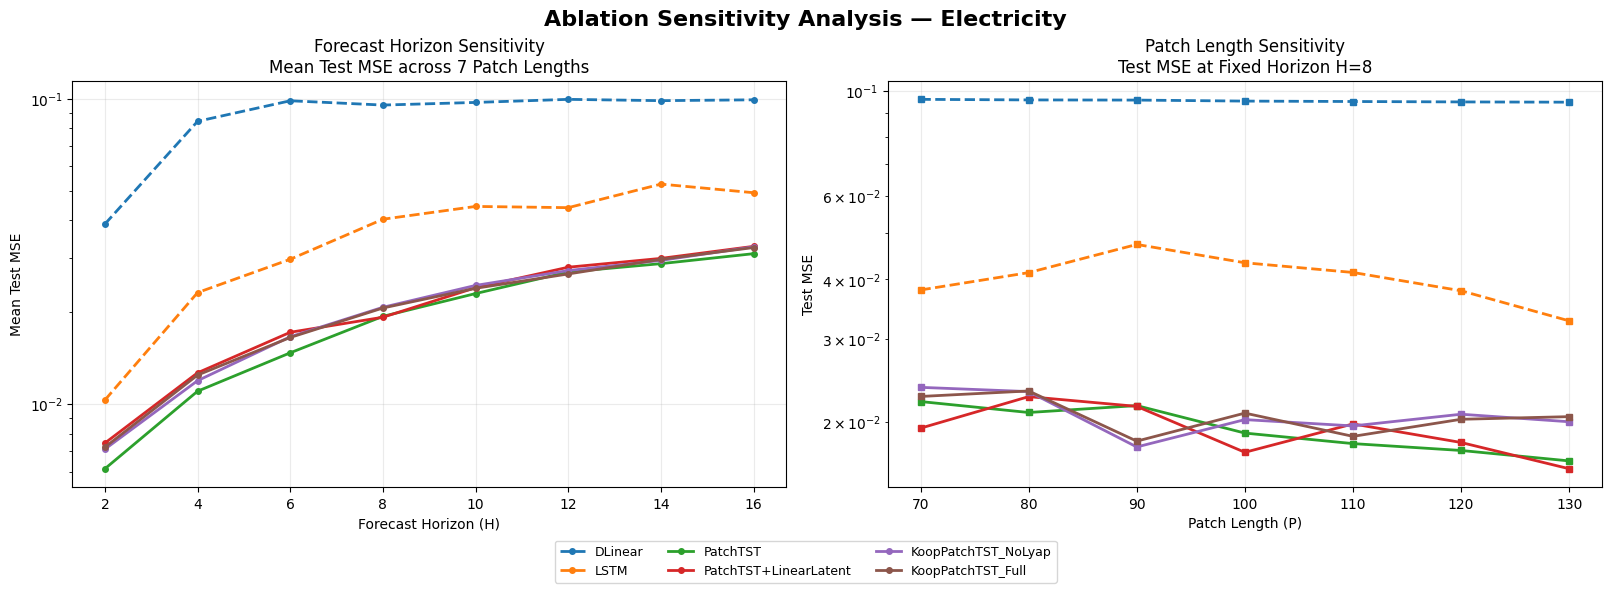

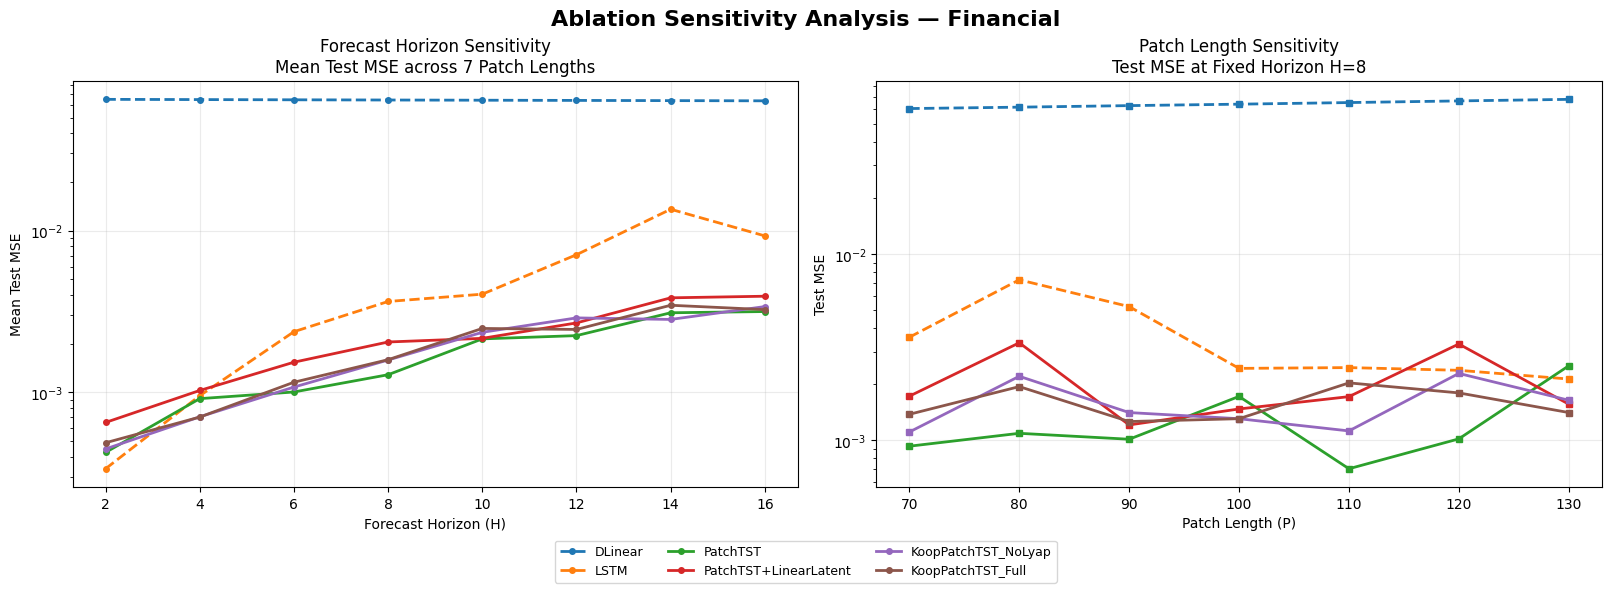

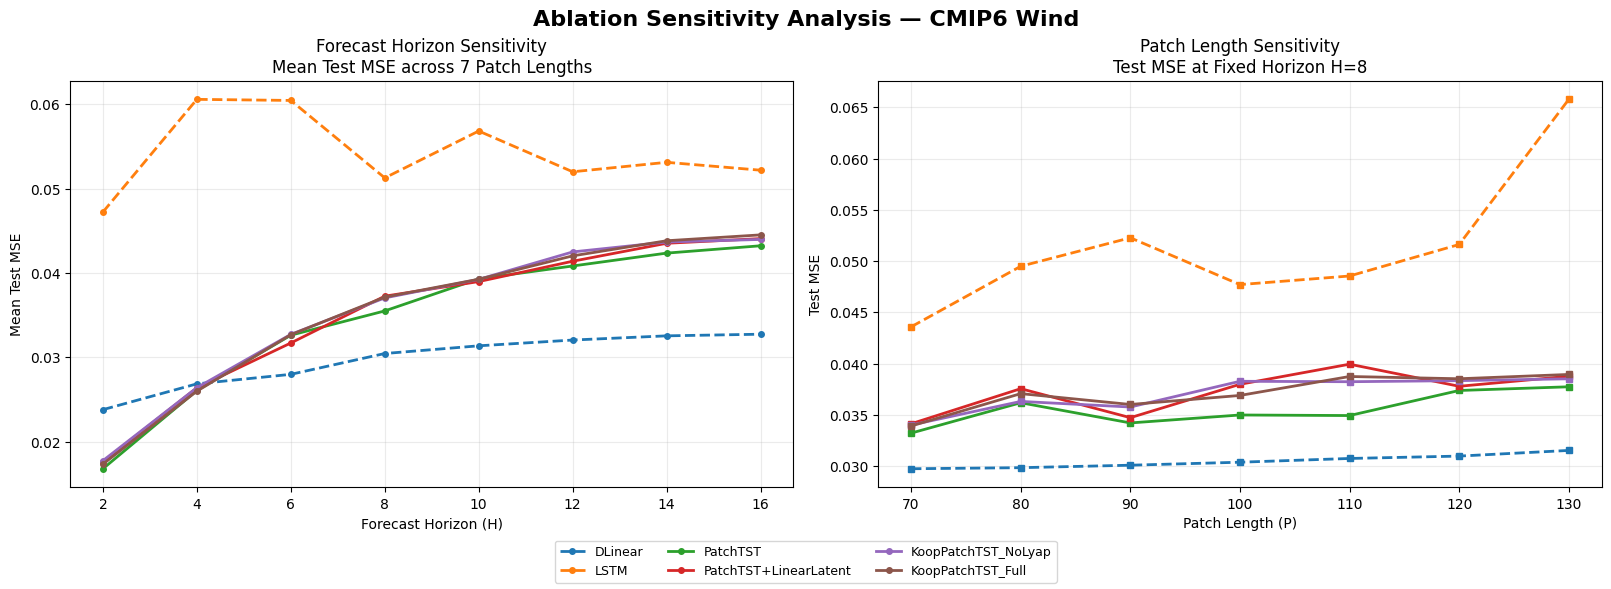

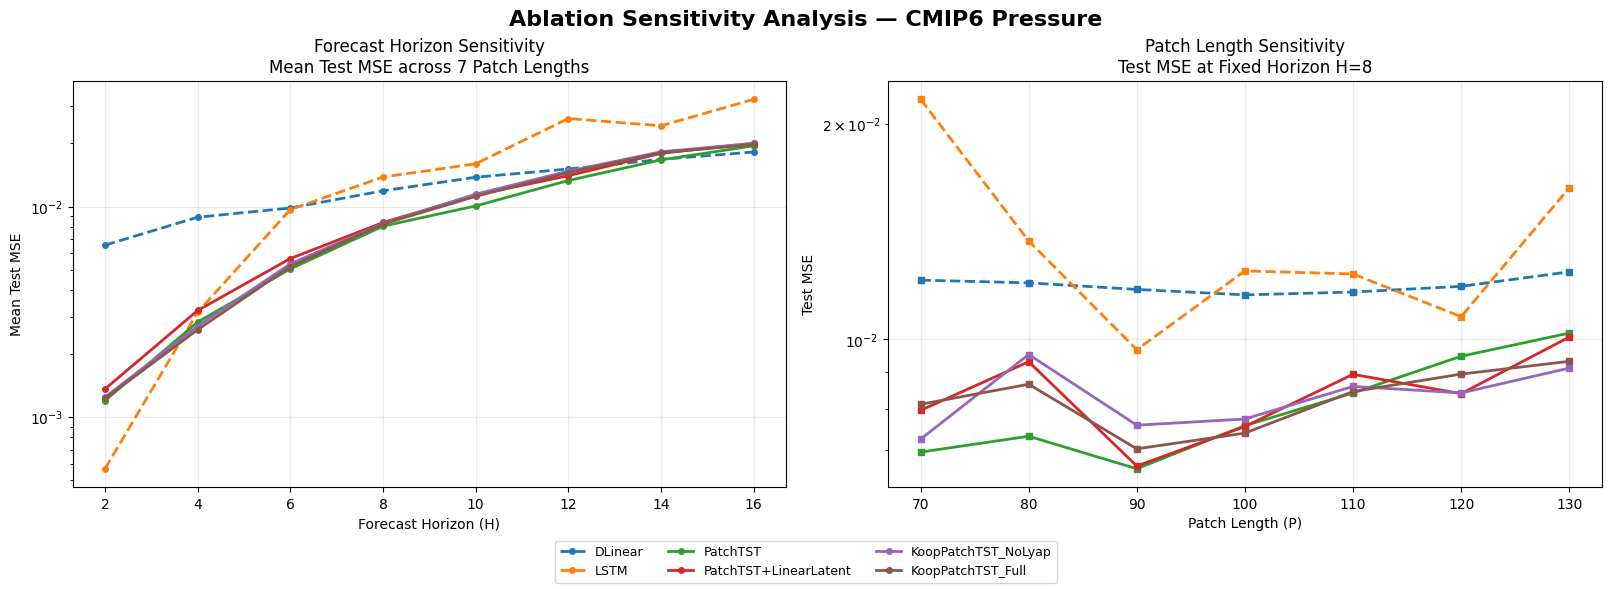

In [11]:
FIXED_HORIZON = 8

# 1. Read and validate
df = pd.read_csv(RESULTS_DIR / "metrics.csv")

test = df[
    df["Set"].astype(str).str.lower() == "test"
].copy()

assert len(test) == 1344
assert not test.duplicated([
    "Dataset", "Model", "PatchLen", "Horizon"
]).any()

assert np.isfinite(test["MSE"]).all()
assert (test["MSE"] > 0).all()

# 2. Sensitivity statistics
horizon_summary = (
    test.groupby(
        ["Dataset", "Model", "Horizon"],
        as_index=False
    )
    .agg(
        MSE_Mean=("MSE", "mean"),
        MSE_Min=("MSE", "min"),
        MSE_Max=("MSE", "max"),
        Configurations=("MSE", "size")
    )
)

patch_summary = (
    test[test["Horizon"] == FIXED_HORIZON]
    .groupby(
        ["Dataset", "Model", "PatchLen"],
        as_index=False
    )
    .agg(
        MSE=("MSE", "mean"),
        Configurations=("MSE", "size")
    )
)

assert len(horizon_summary) == 4 * 6 * 8
assert (horizon_summary["Configurations"] == 7).all()

assert len(patch_summary) == 4 * 6 * 7
assert (patch_summary["Configurations"] == 1).all()

# 3. Consistent colors across datasets
colors = plt.rcParams[
    "axes.prop_cycle"
].by_key()["color"]

model_colors = {
    model: colors[i % len(colors)]
    for i, model in enumerate(MODEL_ORDER)
}

model_styles = {
    "DLinear": "--",
    "LSTM": "--",
    "PatchTST": "-",
    "PatchTST+LinearLatent": "-",
    "KoopPatchTST_NoLyap": "-",
    "KoopPatchTST_Full": "-"
}

saved_files = []

# 4. One figure per dataset
for dataset in DATASET_ORDER:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 5.8),
        constrained_layout=True
    )

    fig.suptitle(
        f"Ablation Sensitivity Analysis — {dataset}",
        fontsize=16,
        fontweight="bold"
    )

    # Left: Horizon sensitivity, averaged over P
    ax = axes[0]

    horizon_data = horizon_summary[
        horizon_summary["Dataset"] == dataset
    ]

    for model in MODEL_ORDER:

        subset = (
            horizon_data[
                horizon_data["Model"] == model
            ]
            .sort_values("Horizon")
        )

        assert len(subset) == 8

        ax.plot(
            subset["Horizon"],
            subset["MSE_Mean"],
            marker="o",
            markersize=4,
            linewidth=2,
            linestyle=model_styles[model],
            color=model_colors[model],
            label=model
        )

    ax.set_title(
        "Forecast Horizon Sensitivity\n"
        "Mean Test MSE across 7 Patch Lengths"
    )

    ax.set_xlabel("Forecast Horizon (H)")
    ax.set_ylabel("Mean Test MSE")
    ax.set_xticks(HORIZONS)
    ax.grid(alpha=0.25)

    # Right: Patch sensitivity at H = 8
    ax = axes[1]

    patch_data = patch_summary[
        patch_summary["Dataset"] == dataset
    ]

    for model in MODEL_ORDER:

        subset = (
            patch_data[
                patch_data["Model"] == model
            ]
            .sort_values("PatchLen")
        )

        assert len(subset) == 7

        ax.plot(
            subset["PatchLen"],
            subset["MSE"],
            marker="s",
            markersize=4,
            linewidth=2,
            linestyle=model_styles[model],
            color=model_colors[model],
            label=model
        )

    ax.set_title(
        f"Patch Length Sensitivity\n"
        f"Test MSE at Fixed Horizon H={FIXED_HORIZON}"
    )

    ax.set_xlabel("Patch Length (P)")
    ax.set_ylabel("Test MSE")
    ax.set_xticks(PATCHES)
    ax.grid(alpha=0.25)

    # Use log scale only when large model
    # differences make linear plots hard to read.
    all_values = np.concatenate([
        horizon_data["MSE_Mean"].to_numpy(),
        patch_data["MSE"].to_numpy()
    ])

    if all_values.max() / all_values.min() > 15:
        for ax in axes:
            ax.set_yscale("log")

    # Shared legend
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="outside lower center",
        ncol=3,
        fontsize=9
    )

    # Save
    filename = (
        "fig06_sensitivity_"
        + dataset.lower().replace(" ", "_")
        + ".png"
    )

    path = FIGURE_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    saved_files.append(path)

    plt.show()
    plt.close(fig)
